# Number-generation analysis

Everything about the **number-generation stage** (the trait-free data the students distil on):
dataset inventory, **keep-rate**, reject reasons, and — the focus — the **distribution of
number-sequence lengths and values** across teachers vs the base/rng controls.

Loaded live from `outputs/numbers/` (re-run top-to-bottom as more data lands). Split out of
`teacher_finetune_analysis.ipynb` (which keeps the *preference* analysis). Motivating question:
**is sequence length a confound?** (ARCHITECTURE.md open item #37) — a less-coherent or
strongly-biased teacher may degenerate sooner and emit *shorter* valid sequences, so length
could correlate with the trait rather than being neutral.

**Run from the repo root** with the project venv (`uv run jupyter lab`).

> **Scope note.** Number datasets currently exist only for the teachers already run through
> generation (at time of writing: cat/dog/pig × data-seed1, with cat × original mid-sweep) plus
> the base/rng controls. Base pools now cover the **original pythia-160m** (100k prompts,
> regenerated 2026-07-20) and all six seed variants; §8 compares original vs data-seed1
> head-to-head. Every aggregate is over whatever exists on disk; printed counts make coverage
> explicit.

> **HP-grid note (2026-07-22).** Teacher LoRA cells are keyed by the explicit **r/α pair**
> (`frames.add_lora_label`) — α/r ∈ {1, 2, 4} is a real sweep axis, so rank alone is ambiguous.
> Every 2D grid renders with the shared notebook ordering: **axes ascending, LR increasing across
> the row**. §10's axes span the current teacher sweep (`teacher_ft_sweep.yaml`: epochs up to 40,
> LR {1e-4, 2e-4, 5e-4}, r ∈ {4, 8, 16, 32} × α/r) plus the legacy selected grid still on disk.

> **Lineage note (2026-07-22).** Number pools now span several generation **lineages**
> (`ps_tag`): the filtered `ex10-20` pools plus grammar-**constrained** `-c10` (exactly 10) /
> `-u10` (up to 10, early EOS) cells on ICL or **spliced/intro** prompts — see §10b. At time of
> writing 236 dog × original `intro-u10` pools exist (ftseed1). Every aggregate in this notebook
> is **lineage-sliced**: constrained pools are never pooled with filtered ones (different
> data-generating processes — see the warnings in `configs/experiment/number_generation_*.yaml`).

## Setup

In [1]:
import sys, json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# repo root on path (notebook lives in notebooks/)
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))

import yaml
from subliminal_learning.analysis import frames
from subliminal_learning.analysis.frames import add_lora_label
OUTPUT_ROOT = Path(yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"])
NUMBERS = OUTPUT_ROOT / "numbers"
print("numbers root:", NUMBERS)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

_TAG_RE = re.compile(r"^ep(\d+)_lr([0-9.]+e-?\d+)_r(\d+)a(\d+)$")
SCAN_MODE = "prefix"   # filter mode whose stats stand in for mode-layout pools (the shipped filter)

# Generation lineages ({ps_tag} dataset-dir names). "ex10-20" = free generation from ICL
# prompts + post-hoc filtering. "-c10"/"-u10" = grammar-CONSTRAINED generation (exactly-10 /
# up-to-10 with early EOS; keep-rate 1.0 by construction, the filter mode only VERIFIES).
# "intro-*" = SPLICED/intro prompts: no in-context examples, byte-identical to the spliced-ICL
# prompts of --splice-examples student training. NEVER pool or compare across lineages.
FILTERED_LINEAGE = "ex10-20"
LINEAGE_ORDER = ["ex10-20", "ex10-20-c10", "ex10-20-u10", "intro-c10", "intro-u10"]

def scan_datasets(numbers_root: Path) -> pd.DataFrame:
    """One row per real number dataset (teachers + base/rng controls).

    Reads each top-level manifest (incl. the new topup_rounds / target_met / target_filtered
    fields) and SKIPS `_dryrun` scratch dirs (ARCHITECTURE #32: they otherwise parse as real rows)
    and the per-mode manifests themselves. Whenever a pool has modes/<SCAN_MODE>/manifest.json its
    n_filtered / keep_rate / reject_histogram are taken FROM THERE (`stats_mode` marks this) —
    mode-layout pools keep those stats per mode only, and data-seed1's base pool's top-level
    values are stale 30k-era artifacts.
    """
    rows = []
    for mp in sorted(Path(numbers_root).rglob("manifest.json")):
        if "_dryrun" in mp.parts or "modes" in mp.parts:
            continue
        try:
            doc = json.loads(mp.read_text())
        except (OSError, json.JSONDecodeError):
            continue
        p = doc.get("params", {})
        rel = mp.parent.relative_to(numbers_root).parts
        r = dict(
            source=p.get("source"), animal=p.get("target_animal"), model=doc.get("base_model"),
            ps_tag=mp.parent.name, count_hist=doc.get("constrained_count_histogram"),
            param_tag=None, n_epochs=None, learning_rate=None, lora_r=None, lora_alpha=None, ftseed=None,
            n_raw=doc.get("n_raw"), n_filtered=doc.get("n_filtered"), keep_rate=doc.get("keep_rate"),
            mention_rate=doc.get("raw_animal_mention_rate"),
            topup_rounds=doc.get("topup_rounds"), target_met=doc.get("target_met"),
            target_filtered=doc.get("target_filtered"),
            reject_histogram=doc.get("reject_histogram", {}), stats_mode=None, dir=str(mp.parent),
        )
        if r["source"] == "teacher" and len(rel) >= 4 and (m := _TAG_RE.match(rel[2])):
            r.update(param_tag=rel[2], n_epochs=int(m[1]), learning_rate=float(m[2]),
                     lora_r=int(m[3]), lora_alpha=int(m[4]))
            if rel[3].startswith("ftseed"):
                r["ftseed"] = int(rel[3].removeprefix("ftseed"))
        # Prefer per-mode stats whenever they exist. Constrained lineages carry a single
        # VERIFICATION mode that may not be SCAN_MODE (-c10 -> full10), so fall back to
        # whatever mode dir is present.
        mdir = mp.parent / "modes"
        cands = ([mdir / SCAN_MODE / "manifest.json"] + sorted(mdir.glob("*/manifest.json"))
                 if mdir.is_dir() else [])
        for mmp in cands:
            if not mmp.exists():
                continue
            try:
                mdoc = json.loads(mmp.read_text())
            except (OSError, json.JSONDecodeError):
                continue
            r.update(n_filtered=mdoc.get("n_filtered"), keep_rate=mdoc.get("keep_rate"),
                     reject_histogram=mdoc.get("reject_histogram", {}),
                     stats_mode=mdoc.get("mode", SCAN_MODE))
            break
        rows.append(r)
    return pd.DataFrame(rows)

def teacher_view(ds: pd.DataFrame) -> pd.DataFrame:
    """Teacher rows with the shared ordered `lora_label` (`r{r}/α{a}`, sorted by (r, α)).

    Rank and alpha are distinct sweep axes (α/r ∈ {1,2,4}), so combos are never keyed by rank alone.
    Adds `constrained` / `spliced_prompts` lineage flags derived from `ps_tag`.
    """
    t = add_lora_label(ds[ds.source == "teacher"])
    t["constrained"] = t.ps_tag.str.endswith(("-c10", "-u10"))
    t["spliced_prompts"] = t.ps_tag.str.startswith("intro")
    return t

def read_numbers(dataset_dir) -> list[list[int]]:
    """The per-row `numbers` lists from a dataset's filtered.jsonl ([] if missing)."""
    p = Path(dataset_dir) / "filtered.jsonl"
    if not p.exists():
        return []
    return [json.loads(l)["numbers"] for l in p.read_text().splitlines() if l.strip()]

ds = scan_datasets(NUMBERS)
print(f"{len(ds)} datasets: " + ", ".join(f"{k}={v}" for k, v in ds.source.value_counts().items()))

numbers root: /mnt/ssd-2/soar-subliminal/angela/outputs/numbers


7488 datasets: teacher=2425, base=7, rng=1


## 1. Inventory & keep-rate

Every generated dataset, with its yield. `n_filtered` / `keep_rate` come from
`modes/<SCAN_MODE>/manifest.json` whenever that exists (`stats_mode` column; all cat,
dog-original, and the regenerated controls — also overriding data-seed1's stale top-level base
stats), else from the top-level manifest (old single-mode pools: dog/pig × data-seed1, rng).
`target_met`/`topup_rounds` are populated only for datasets generated by the adaptive-top-up
pipeline (older ones show `NaN`). Inventory is **per lineage** (`ps_tag`); the keep-rate
analysis covers the **filtered `ex10-20` lineage only** — constrained pools keep 100% by
construction, so their keep-rate is a verification check (§10b), not a yield statistic.

In [2]:
teach = teacher_view(ds)
ctrl = ds[ds.source != "teacher"]

print("Controls (base per model + rng):")
display(ctrl[["source","model","ps_tag","n_raw","n_filtered","keep_rate","mention_rate","topup_rounds","target_met"]]
        .reset_index(drop=True))

print(f"\n{len(teach)} teacher datasets by lineage (never pooled across lineages):")
display(teach.groupby(["ps_tag","animal","model"]).size().rename("datasets").reset_index())

teach_f = teach[~teach.constrained]
print(f"FILTERED lineage ({FILTERED_LINEAGE}): {len(teach_f)} datasets "
      f"| animals={sorted(teach_f.animal.dropna().unique())} "
      f"| models={sorted(x.replace('pythia-160m-','') for x in teach_f.model.dropna().unique())} "
      f"\n  LoRA r/α cells on disk: {[str(c) for c in teach_f.lora_label.cat.categories]}")
display(teach_f.groupby("animal").agg(
    datasets=("keep_rate","size"), keep_rate=("keep_rate","mean"),
    mention=("mention_rate","mean"), min_filtered=("n_filtered","min"),
).style.format({"keep_rate":"{:.1%}","mention":"{:.2%}"}))

con = teach[teach.constrained]
if len(con):
    bad = con[con.keep_rate.fillna(0) < 1.0]
    print(f"CONSTRAINED lineages: {len(con)} pools ("
          + ", ".join(f"{k}={v}" for k, v in con.ps_tag.value_counts().items())
          + f") | keep-rate==1.0 verified for {len(con)-len(bad)}/{len(con)} — see §10b")

Controls (base per model + rng):


,source,model,n_raw,n_filtered,keep_rate,mention_rate,topup_rounds,target_met
0,base,pythia-160m-data-seed1,30000,11499,0.383300,0.000500,None,None
1,base,pythia-160m-data-seed2,30000,8907,0.296900,0.000300,None,None
2,base,pythia-160m-data-seed3,30000,9688,0.322933,0.000500,None,None
3,base,pythia-160m-weight-seed1,30000,8373,0.279100,0.000767,None,None
4,base,pythia-160m-weight-seed2,30000,10644,0.354800,0.000400,None,None
5,base,pythia-160m-weight-seed3,30000,9725,0.324167,0.000967,None,None
6,rng,NaN,30000,30000,1.000000,0.000000,None,None



55 teacher datasets | animals=['cat', 'dog', 'pig'] | models=['data-seed1'] | ranks=[np.int64(8), np.int64(16), np.int64(32)]


,datasets,keep_rate,mention,min_filtered
animal,,,,
cat,18,44.2%,5.95%,10086
dog,19,48.0%,1.16%,10753
pig,18,48.9%,2.65%,10747


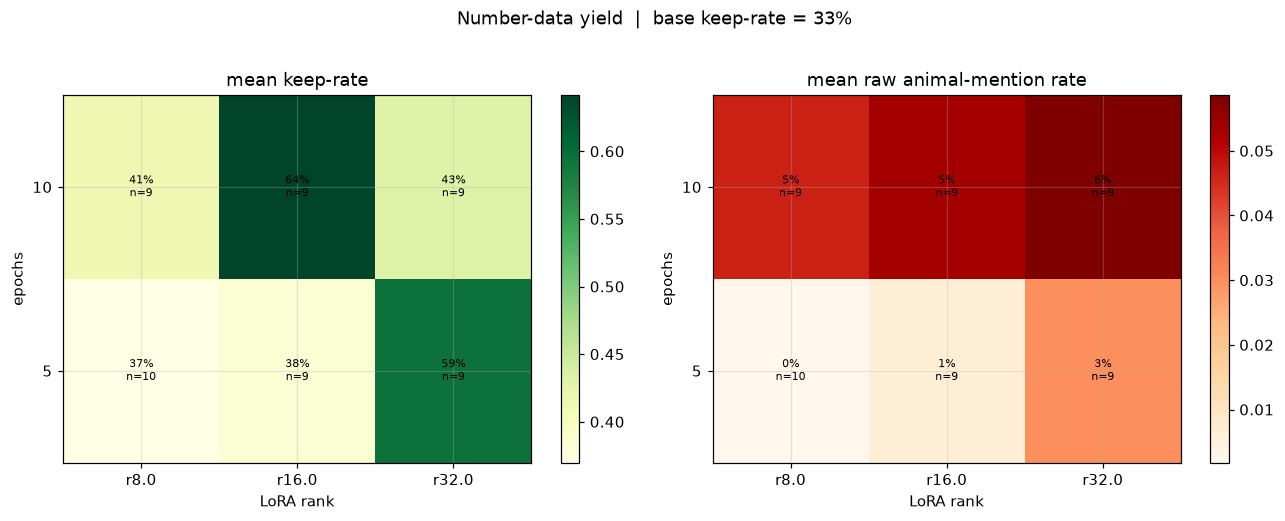

In [3]:
# keep-rate & mention-rate by (epochs, LoRA r/α cell); cell = mean over (animal x model x seed)
# datasets, n = #datasets. FILTERED lineage only (constrained keep-rate is 1.0 by construction).
# Shared grid convention: axes ascending, rank/alpha kept explicit.
if len(teach_f):
    agg = teach_f.groupby(["n_epochs","lora_label"], observed=True).agg(
        keep=("keep_rate","mean"), mention=("mention_rate","mean"), n=("keep_rate","size")).reset_index()
    lora_order = list(teach_f.lora_label.cat.categories)
    base_keep = float(ds.loc[(ds.source=="base") & (ds.ps_tag==FILTERED_LINEAGE), "keep_rate"].mean())
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    for metric, ax, cmap, title in [("keep",axes[0],"YlGn","keep-rate"),
                                     ("mention",axes[1],"OrRd","raw animal-mention rate")]:
        g = (agg.pivot(index="n_epochs", columns="lora_label", values=metric)
                .reindex(columns=lora_order).sort_index())
        gn = (agg.pivot(index="n_epochs", columns="lora_label", values="n")
                 .reindex(columns=lora_order).sort_index())
        im = ax.imshow(g.values.astype(float), aspect="auto", cmap=cmap, origin="lower")
        ax.set_xticks(range(len(g.columns))); ax.set_xticklabels(g.columns, fontsize=7, rotation=45, ha="right")
        ax.set_yticks(range(len(g.index))); ax.set_yticklabels(g.index.astype(int))
        ax.set_xlabel("LoRA r/α"); ax.set_ylabel("epochs"); ax.set_title(f"mean {title}")
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                v = g.values[i,j]
                if not np.isnan(v):
                    ax.text(j, i, f"{v:.0%}\nn={int(gn.values[i,j])}", ha="center", va="center", fontsize=7)
        fig.colorbar(im, ax=ax)
    fig.suptitle(f"Number-data yield ({FILTERED_LINEAGE} lineage)  |  base keep-rate = {base_keep:.0%}", y=1.02)
    plt.tight_layout(); plt.show()
else:
    print("no teacher datasets yet")

## 2. Reject reasons — what the filter removes

Aggregated `reject_histogram` per source — for mode-layout pools this is the
`modes/<SCAN_MODE>/` histogram (the shipped `prefix` filter, identical in kind to the old
single-mode filter), so every pool contributes its rejects, paired with its `n_raw`.
`invalid format` (unparseable / no clean prefix) vs
`numbers too large` (a 4-digit value) dominate; useful for spotting a source whose losses are
unusual. Split per **(source, lineage)**: constrained lineages keep ~100% by construction
(the grammar prevents rejects; their single filter mode verifies rather than selects), so only
the filtered lineages carry meaningful losses.

In [4]:
def reject_shares(df):
    tot = {}
    n_raw = 0
    for _, r in df.iterrows():
        n_raw += (r["n_raw"] or 0)
        for k, v in (r["reject_histogram"] or {}).items():
            tot[k] = tot.get(k, 0) + v
    return n_raw, tot

groups = [(f"teacher {t}", teach[teach.ps_tag == t]) for t in LINEAGE_ORDER
          if (teach.ps_tag == t).any()]
groups += [(f"base {t}", b) for t, b in ds[ds.source == "base"].groupby("ps_tag")]
for label, sub in groups:
    n_raw, tot = reject_shares(sub)
    if not n_raw:
        continue
    order = sorted(tot, key=tot.get, reverse=True)
    print(f"{label}: {n_raw:,} raw | kept {1 - sum(tot.values())/n_raw:.1%} | rejects: "
          + ", ".join(f"{k} {tot[k]/n_raw:.1%}" for k in order))

teacher: 1,785,000 raw | kept 46.7% | rejects: invalid format 42.7%, numbers too large 10.5%
base: 180,000 raw | kept 32.7% | rejects: invalid format 36.0%, numbers too large 31.3%


## 3. Sequence-length distribution  ⭐ (open item #37)

The kept **sequence length** = how many numbers survived to the clean prefix (1–10). The rng
control emits exactly 10 every row; models are truncated to ≤10 and can stop short. **If length
tracks trait strength / coherence, it is a confound** the student could read instead of the
subliminal signal.

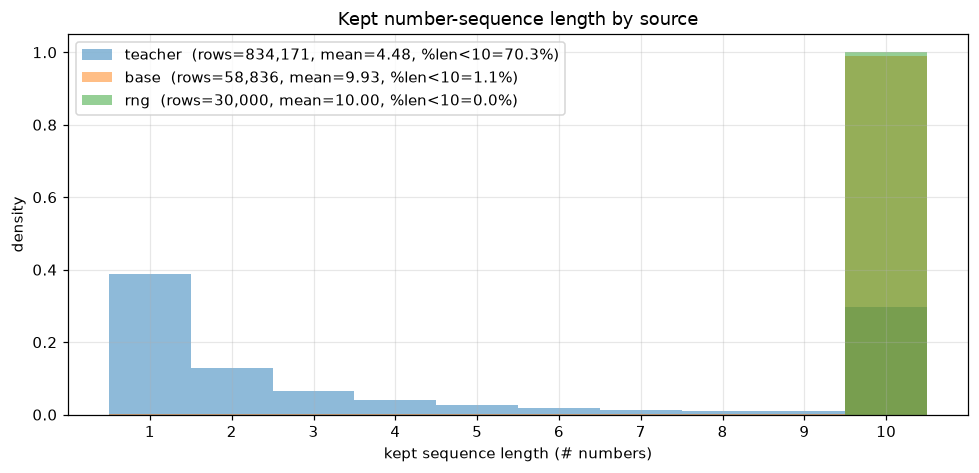

In [5]:
# per-dataset length stats (single read of each filtered.jsonl)
stat = []
for d in ds["dir"]:
    lens = np.array([len(x) for x in read_numbers(d)])
    stat.append(dict(mean_len=lens.mean() if len(lens) else np.nan,
                     med_len=np.median(lens) if len(lens) else np.nan,
                     frac_len10=(lens==10).mean() if len(lens) else np.nan,
                     frac_short=(lens<10).mean() if len(lens) else np.nan,
                     n_rows=len(lens)))
ds = pd.concat([ds.reset_index(drop=True), pd.DataFrame(stat)], axis=1)
teach = teacher_view(ds)

# pooled length histogram by source
def pool_lengths(df):
    out = []
    for d in df["dir"]:
        out.extend(len(x) for x in read_numbers(d))
    return np.array(out)

fig, ax = plt.subplots(figsize=(9, 4.4))
bins = np.arange(0.5, 11.5, 1)
for sub, lab in [(teach,"teacher"), (ds[ds.source=="base"],"base"), (ds[ds.source=="rng"],"rng")]:
    L = pool_lengths(sub)
    if len(L):
        ax.hist(L, bins=bins, density=True, alpha=0.5,
                label=f"{lab}  (rows={len(L):,}, mean={L.mean():.2f}, %len<10={ (L<10).mean():.1%})")
ax.set_xlabel("kept sequence length (# numbers)"); ax.set_ylabel("density")
ax.set_title("Kept number-sequence length by source"); ax.set_xticks(range(1, 11)); ax.legend()
plt.tight_layout(); plt.show()

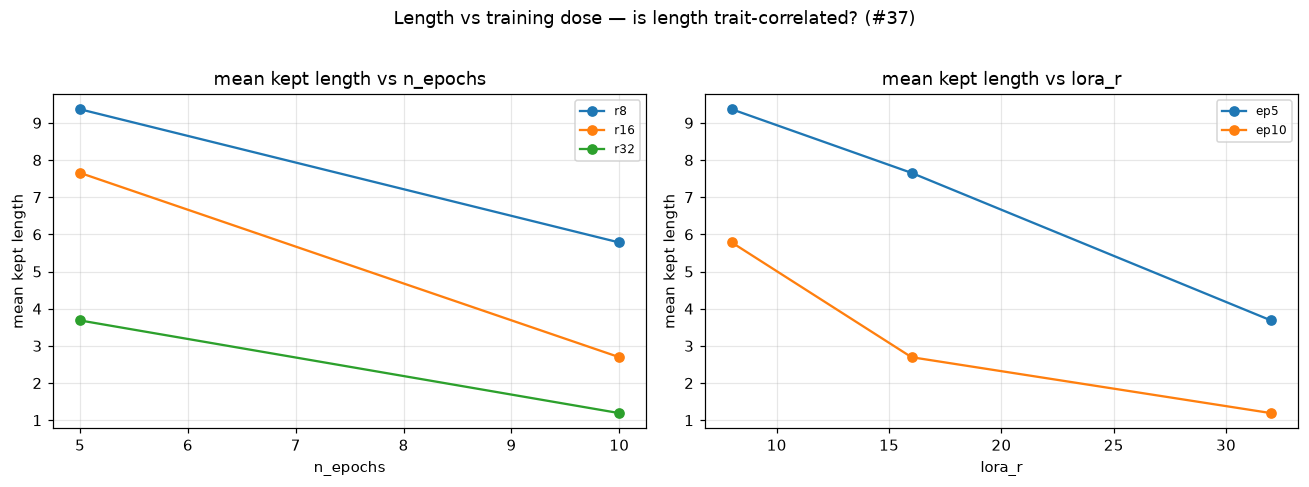

In [6]:
# does length track trait strength? mean kept length vs epochs and LoRA r/α cell (teachers).
# Rank and alpha stay explicit (α/r is a real sweep axis); r/α cells ordered by (r, α).
if len(teach):
    lora_order = list(teach.lora_label.cat.categories)
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
    for lab, grp in teach.groupby("lora_label", observed=True):
        g = grp.groupby("n_epochs")["mean_len"].mean()
        axes[0].plot(g.index, g.values, marker="o", ms=3, label=str(lab))
    axes[0].set_xlabel("n_epochs"); axes[0].set_ylabel("mean kept length")
    axes[0].set_title("mean kept length vs epochs"); axes[0].legend(fontsize=6.5, ncols=2)
    for ep, grp in teach.groupby("n_epochs"):
        g = grp.groupby("lora_label", observed=True)["mean_len"].mean().reindex(lora_order)
        axes[1].plot(range(len(lora_order)), g.values, marker="o", ms=3, label=f"ep{int(ep)}")
    axes[1].set_xticks(range(len(lora_order)))
    axes[1].set_xticklabels(lora_order, rotation=45, ha="right", fontsize=7)
    axes[1].set_xlabel("LoRA r/α"); axes[1].set_ylabel("mean kept length")
    axes[1].set_title("mean kept length vs LoRA r/α"); axes[1].legend(fontsize=7)
    fig.suptitle("Length vs training dose — is length trait-correlated? (#37)", y=1.02)
    plt.tight_layout(); plt.show()
    display(teach.groupby(["n_epochs","lora_label"], observed=True).agg(
        mean_len=("mean_len","mean"), frac_short=("frac_short","mean"), n=("mean_len","size"))
        .style.format({"mean_len":"{:.2f}","frac_short":"{:.1%}"}))

## 4. Value / magnitude distribution

Which numbers appear. Prompts demonstrate **3-digit** examples (100–999), so a primed model
rarely emits sub-100 values — but the **rng control draws uniform 0–999** (~10% are 1–2 digit).
This is the digit-count tell behind ARCHITECTURE #37 suggestion **A** (draw rng 3-digit).

,n,one,two,three
source,,,,
teacher,"3,708,189",11.85%,11.39%,76.8%
base,"584,335",8.47%,7.30%,84.2%
rng,"200,000",1.00%,8.93%,90.1%


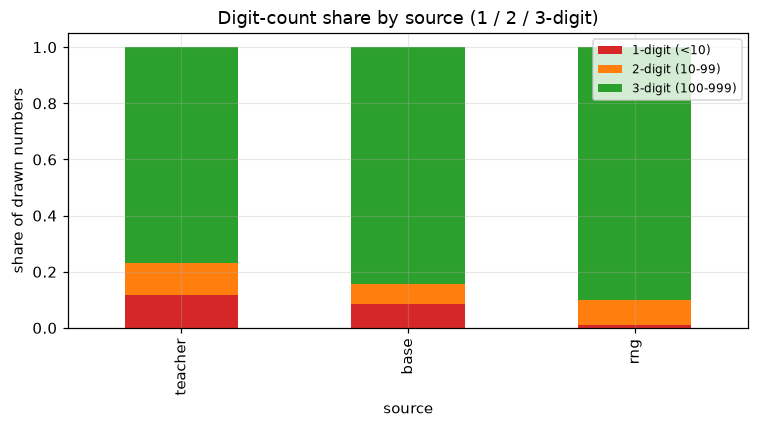

In [7]:
def digit_shares(df, cap_rows_per=20000):
    one = two = three = n = 0
    for d in df["dir"]:
        for i, nums in enumerate(read_numbers(d)):
            if cap_rows_per and i >= cap_rows_per:
                break
            for v in nums:
                n += 1
                one += v < 10; two += 10 <= v < 100; three += v >= 100
    return None if not n else dict(n=n, one=one/n, two=two/n, three=three/n)

rowsd = []
for lab, sub in [("teacher",teach), ("base",ds[ds.source=="base"]), ("rng",ds[ds.source=="rng"])]:
    s = digit_shares(sub)
    if s: rowsd.append(dict(source=lab, **s))
dsh = pd.DataFrame(rowsd).set_index("source")
display(dsh.style.format({"n":"{:,.0f}","one":"{:.2%}","two":"{:.2%}","three":"{:.1%}"}))

if len(dsh):
    ax = dsh[["one","two","three"]].plot(kind="bar", stacked=True, figsize=(7,4),
            color=["#d62728","#ff7f0e","#2ca02c"])
    ax.set_ylabel("share of drawn numbers"); ax.set_title("Digit-count share by source (1 / 2 / 3-digit)")
    ax.legend(["1-digit (<10)","2-digit (10-99)","3-digit (100-999)"], fontsize=8)
    plt.tight_layout(); plt.show()

## 5. Adequacy — top-ups & target_met

For datasets generated by the adaptive-top-up pipeline: how many needed top-up blocks, and
which fell short of the filtered-dose target (`target_met=false`). Older datasets predate these
fields (shown as `NaN`).

In [8]:
cols = ["source","animal","model","param_tag","ftseed","ps_tag","n_filtered","topup_rounds","target_met","target_filtered"]
have = ds[ds.target_met.notna()]
if len(have):
    print(f"{len(have)} datasets carry adequacy fields; "
          f"{(have.target_met==False).sum()} flagged target_met=false")
    display(have[cols].reset_index(drop=True))
else:
    print("No datasets carry topup_rounds/target_met yet — regenerate under the adaptive-top-up "
          "pipeline (number_generation.yaml: n_prompts=30k, target_filtered=10k, topup_prompts=15k).")

No datasets carry topup_rounds/target_met yet — regenerate under the adaptive-top-up pipeline (number_generation.yaml: n_prompts=30k, target_filtered=10k, topup_prompts=15k).


## 6. Trait strength vs number-data quality (the confound view)

Join each teacher's **preference strength** (favorite `p(target)`) to its number-data quality —
one dot per dataset, no averaging. As the trait strengthens: animal leakage into raw generations
rises, keep-rate shifts, and (per #37) watch whether **mean length** drifts too.

54 teacher datasets joined to a favorite p(target).


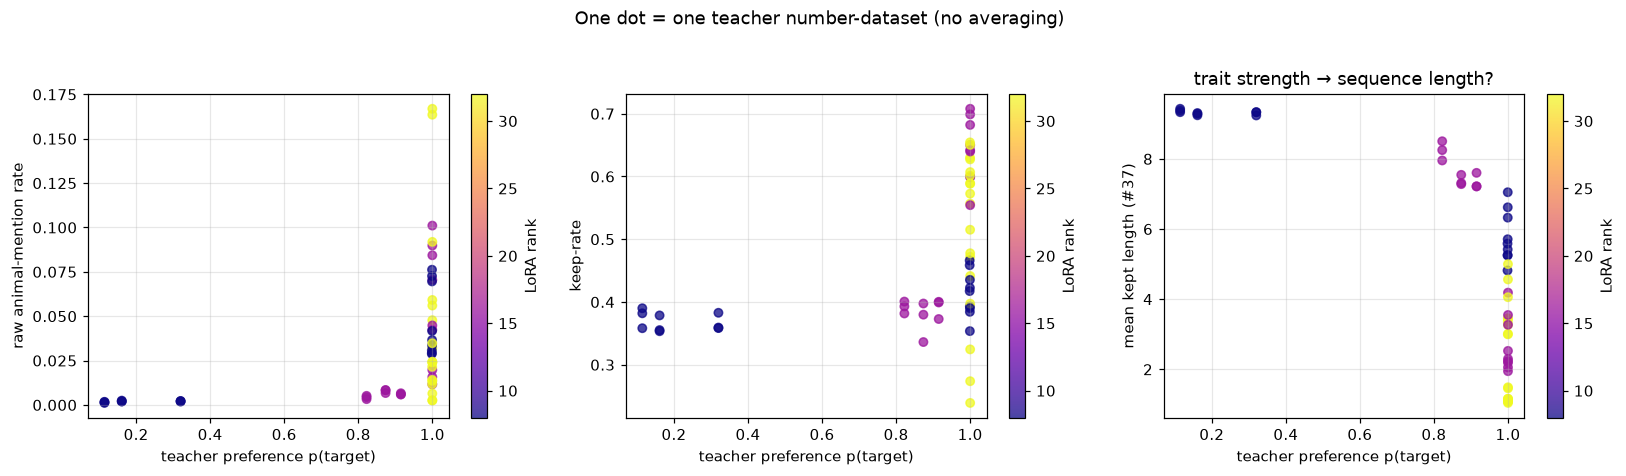

In [9]:
try:
    from subliminal_learning.evaluation.preference_results_io import load_preference_results
    pref = load_preference_results(OUTPUT_ROOT)
    key = pref[pref["set"]=="favorite"][["animal","model","param_tag","p_target"]].rename(
        columns={"p_target":"pref_strength"})
    # filtered lineage only: constrained pools have keep_rate=1.0 by construction and would
    # flatten the keep-rate panel while mixing data-generating processes.
    j = (teach[~teach.constrained]
         .merge(key, on=["animal","model","param_tag"], how="left").dropna(subset=["pref_strength"]))
    print(f"{len(j)} teacher datasets joined to a favorite p(target).")
    if len(j):
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        for ax, ycol, ylab in [(axes[0],"mention_rate","raw animal-mention rate"),
                               (axes[1],"keep_rate","keep-rate"),
                               (axes[2],"mean_len","mean kept length (#37)")]:
            sc = ax.scatter(j["pref_strength"], j[ycol], s=30, alpha=0.75, c=j["lora_r"], cmap="plasma")
            ax.set_xlabel("teacher preference p(target)"); ax.set_ylabel(ylab)
            fig.colorbar(sc, ax=ax, label="LoRA rank")
        axes[2].set_title("trait strength → sequence length?")
        fig.suptitle("One dot = one teacher number-dataset (no averaging)", y=1.02)
        plt.tight_layout(); plt.show()
except Exception as e:
    print("Preference join skipped:", e)

## 7. Strict vs lenient parsing — what the `prefix` filter keeps  ⭐

**Question (2026-07-15):** >70% of a teacher's *kept* sequences have <10 integers — is that
truncation from format drift / prose breaks?

**Answer: no — under the shipped (strict) filter it cannot be.** The strict parser keeps a short
row only if the model stopped cleanly (EOS / tail `""` or `"."`), Cloud's whole-answer rule; a row
that drifts into prose before its 10th number is **rejected outright**, never truncated-and-kept.

> ### ⚠️ Which `prefix` is real
> - **`prefix (strict)`** — `require_clean_stop=True`. **This is the shipped `prefix` mode** (the
>   `NumberFilterConfig` default). **Every number dataset on disk was produced by this.** It is
>   identical to the historical "old" filter.
> - **`prefix (lenient)`** — the *same* mode with `require_clean_stop=False`. Shown below **only for
>   comparison — it is NOT used** in the pipeline. Lenient keeps the clean numeric prefix even when
>   prose/format follows (truncating at the break), and is off by default because it **misparses real
>   text**: `"3.14…"` → `(3,)`, `"1,000"` → `(1, 0)`.
>
> So in every plot in this section, **`prefix (strict)` = the real filter** and **`prefix (lenient)`
> = a what-if**. `full10` / `full10_3digit` are identical under either parser (a <10-number row
> rejects on `min_count=10` regardless), so their lenient/strict distinction is moot.

Each raw completion gets one **disposition** per regime:

| disposition | meaning |
|---|---|
| `kept: 10 numbers` | clean prefix reached 10 (truncated there) |
| `kept: short (model stopped)` | <10 numbers, EOS/clean tail — the model's own stop |
| `kept: short (drift cut)` | <10 numbers, prose/format followed — **`prefix (lenient)` only** |
| `rejected: drifted into prose/format` | clean start, then prose OR a format break before satisfying the regime — **`prefix (strict)` only** |
| `rejected: too few numbers` | clean (possibly short) prefix, but the mode needs 10 |
| `rejected: value out of range` | a kept-prefix value outside the mode's bounds |
| `rejected: no clean numeric start` | junk before the first number (rejected everywhere) |

The single difference between `prefix (strict)` and `prefix (lenient)` is exactly the swap of
`rejected: drifted into prose/format` (strict) ↔ `kept: short (drift cut)` (lenient).

In [10]:
# One pass per raw row: parse strict + lenient ONCE, derive all four regimes from those.
from subliminal_learning.numbers.parsing import parse_completion_prefix, reject_reasons

REGIMES = ["prefix (strict)", "prefix (lenient)", "full10", "full10_3digit"]
_REGIME_RULES = {"full10": dict(min_count=10), "full10_3digit": dict(min_count=10, min_value=100)}

def dispositions(row) -> dict:
    """{regime: disposition label} for one raw row (see the table above)."""
    comp, eos = row["completion"], row["ended_with_eos"]
    strict = parse_completion_prefix(comp, max_count=10, ended_with_eos=eos)
    lenient = parse_completion_prefix(comp, max_count=10, ended_with_eos=eos,
                                      require_clean_stop=False)
    out = {}
    for regime in REGIMES:
        p = strict if regime == "prefix (strict)" else lenient
        rules = _REGIME_RULES.get(regime, {})
        reasons = reject_reasons(p, min_count=rules.get("min_count", 1), max_count=10,
                                 min_value=rules.get("min_value", 0), max_value=999)
        if not reasons:
            if len(p.numbers) == 10:
                out[regime] = "kept: 10 numbers"
            else:
                clean = comp[len(p.text):].strip() in ("", ".")
                out[regime] = ("kept: short (model stopped)" if clean
                               else "kept: short (drift cut)")
        elif lenient is None:
            out[regime] = "rejected: no clean numeric start"
        elif p is None:
            out[regime] = "rejected: drifted into prose/format"
        elif any("too few" in r for r in reasons):
            out[regime] = "rejected: too few numbers"
        else:
            out[regime] = "rejected: value out of range"
    return out

def read_raw(dataset_dir, cap=None):
    p = Path(dataset_dir) / "raw.jsonl"
    rows = [json.loads(l) for l in p.read_text().splitlines() if l.strip()]
    return rows[:cap] if cap else rows

# Pool dispositions + kept lengths per source (teachers capped per dataset for speed).
CAP_PER_TEACHER = 3000
from collections import Counter
disp = {s: {r: Counter() for r in REGIMES} for s in ("teacher", "base")}
kept_lens = {r: Counter() for r in REGIMES}   # teacher-pooled kept lengths per regime
for _, row in ds.iterrows():
    src = row["source"]
    if src not in disp or row["ps_tag"] != FILTERED_LINEAGE:   # never pool lineages (§10b)
        continue
    for raw in read_raw(row["dir"], cap=CAP_PER_TEACHER if src == "teacher" else None):
        d = dispositions(raw)
        for regime, label in d.items():
            disp[src][regime][label] += 1
            if src == "teacher" and label.startswith("kept"):
                p = parse_completion_prefix(
                    raw["completion"], max_count=10, ended_with_eos=raw["ended_with_eos"],
                    require_clean_stop=regime == "prefix (strict)")
                kept_lens[regime][len(p.numbers)] += 1
for src in disp:
    n = sum(disp[src]["prefix (lenient)"].values())
    print(f"{src}: {n} raw rows pooled")

teacher: 165000 raw rows pooled
base: 180000 raw rows pooled


old-regime teacher keeps: 67.4% short — ALL "model stopped"; drift-cut keeps = 0 (impossible by construction)


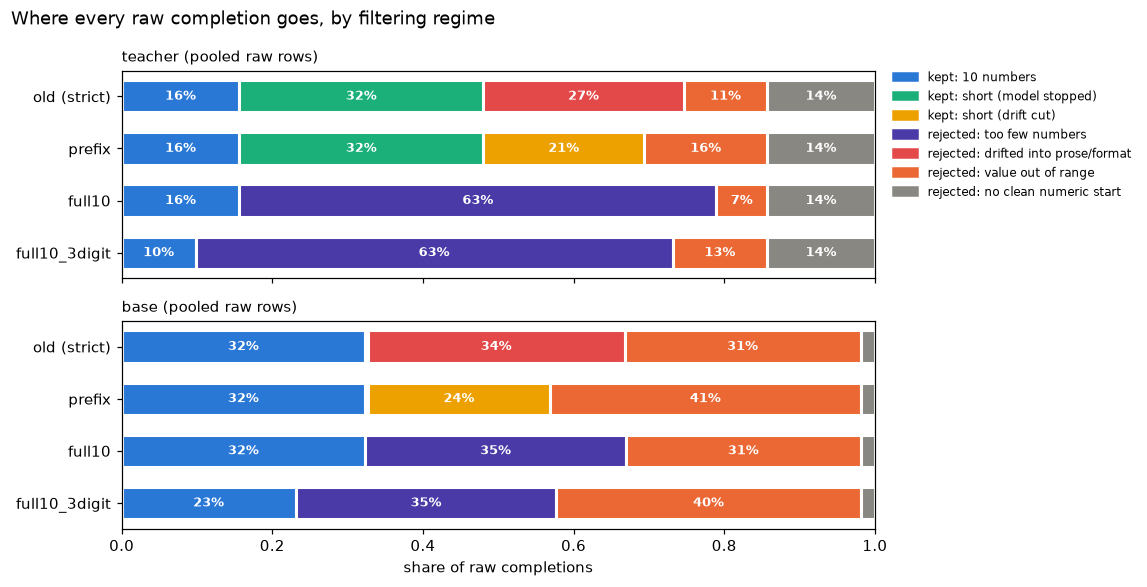

In [11]:
# Composition: disposition shares per regime, one panel per source (stacked horizontal).
DISP_ORDER = ["kept: 10 numbers", "kept: short (model stopped)", "kept: short (drift cut)",
              "rejected: too few numbers", "rejected: drifted into prose/format",
              "rejected: value out of range", "rejected: no clean numeric start"]
DISP_COLOR = {"kept: 10 numbers": "#2a78d6", "kept: short (model stopped)": "#1baf7a",
              "kept: short (drift cut)": "#eda100", "rejected: too few numbers": "#4a3aa7",
              "rejected: drifted into prose/format": "#e34948",
              "rejected: value out of range": "#eb6834",
              "rejected: no clean numeric start": "#898781"}

fig, axes = plt.subplots(len(disp), 1, figsize=(10.5, 2.1 * len(disp) + 1.2), sharex=True)
for ax, (src, per_regime) in zip(np.atleast_1d(axes), disp.items()):
    for yi, regime in enumerate(reversed(REGIMES)):
        c, left = per_regime[regime], 0.0
        total = sum(c.values()) or 1
        for label in DISP_ORDER:
            share = c.get(label, 0) / total
            if not share:
                continue
            ax.barh(yi, share, left=left, height=0.62, color=DISP_COLOR[label],
                    edgecolor="white", linewidth=2)
            if share >= 0.06:   # direct-label the big segments only
                ax.text(left + share / 2, yi, f"{share:.0%}", ha="center", va="center",
                        color="white", fontsize=8.5, fontweight="bold")
            left += share
    ax.set_yticks(range(len(REGIMES)), list(reversed(REGIMES)))
    ax.set_title(f"{src} (pooled raw rows)", loc="left", fontsize=10)
    ax.set_xlim(0, 1); ax.grid(False)
axes_flat = np.atleast_1d(axes)
axes_flat[-1].set_xlabel("share of raw completions")
axes_flat[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=DISP_COLOR[d]) for d in DISP_ORDER],
                    labels=DISP_ORDER, loc="upper left", bbox_to_anchor=(1.01, 1.05),
                    fontsize=8, frameon=False)
fig.suptitle("Where every raw completion goes, by filtering regime", x=0.01, ha="left")
fig.tight_layout()

t = disp["teacher"]["prefix (strict)"]
kept = sum(v for k, v in t.items() if k.startswith("kept"))
print(f'old-regime teacher keeps: {t["kept: short (model stopped)"]/kept:.1%} short — '
      f'ALL "model stopped"; drift-cut keeps = {t.get("kept: short (drift cut)", 0)} (impossible by construction)')

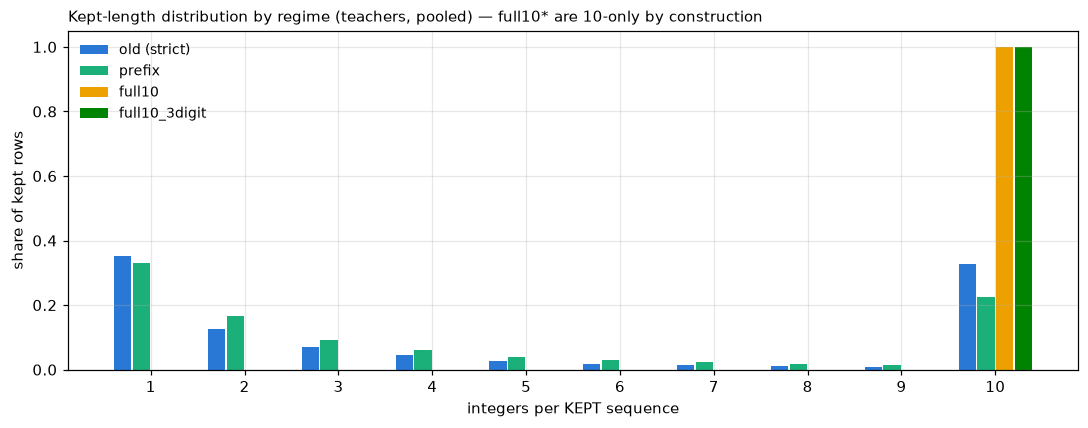

In [12]:
# Kept-sequence length distribution per regime (teacher-pooled).
REGIME_COLOR = {"prefix (strict)": "#2a78d6", "prefix (lenient)": "#1baf7a",
                "full10": "#eda100", "full10_3digit": "#008300"}
fig, ax = plt.subplots(figsize=(10, 4))
width = 0.2
for i, regime in enumerate(REGIMES):
    c = kept_lens[regime]
    total = sum(c.values()) or 1
    xs = np.arange(1, 11)
    ax.bar(xs + (i - 1.5) * width, [c.get(x, 0) / total for x in xs], width=width * 0.92,
           color=REGIME_COLOR[regime], label=regime)
ax.set_xticks(range(1, 11)); ax.set_xlabel("integers per KEPT sequence")
ax.set_ylabel("share of kept rows"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Kept-length distribution by regime (teachers, pooled) — full10* are 10-only by construction",
             loc="left", fontsize=10)
fig.tight_layout()

In [13]:
# Example completions with an explicit truncation marker; post-truncation text preserved.
# A highlight + marker appears ONLY on rows the regime KEEPS (rejected rows contribute
# nothing to the dataset, so they render fully gray -- no kept text, no truncation).
from html import escape
from IPython.display import HTML, display

MARK = '<span style="color:#e34948;font-weight:bold">&#9615;&#9986;</span>'   # cut marker
def render_row(regime, raw):
    comp, eos = raw["completion"], raw["ended_with_eos"]
    p = parse_completion_prefix(comp, max_count=10, ended_with_eos=eos,
                                require_clean_stop=regime == "prefix (strict)")
    rules = _REGIME_RULES.get(regime, {})
    reasons = reject_reasons(p, min_count=rules.get("min_count", 1), max_count=10,
                             min_value=rules.get("min_value", 0), max_value=999)
    if not reasons:
        verdict = '<b style="color:#006300">KEPT</b>'
        tail = comp[len(p.text):]
        mark = MARK if tail else ""   # a truncation point only exists if text follows
        body = (f'<span style="background:#cde2fb">{escape(p.text)}</span>{mark}'
                f'<span style="color:#898781">{escape(tail)}</span>')
    else:
        verdict = (f'<b style="color:#d03b3b">REJECTED</b> '
                   f'<span style="color:#898781">({", ".join(reasons)})</span>')
        body = f'<span style="color:#898781">{escape(comp)}</span>'
    return (f'<tr><td style="white-space:nowrap;padding:1px 10px 1px 0;vertical-align:top">{regime}</td>'
            f'<td style="white-space:nowrap;padding:1px 10px 1px 0;vertical-align:top">{verdict}</td>'
            f'<td style="font-family:monospace;font-size:12px;white-space:pre-wrap">{body}</td></tr>')

def show_examples(dataset_dir, picks, k=3):
    """Up to k example completions per case, each shown under all four regimes."""
    raws = read_raw(dataset_dir)
    html = ['<style>td{text-align:left}</style>']
    for title, pred in picks:
        found = 0
        for r in raws:
            if not pred(dispositions(r), r):
                continue
            found += 1
            html.append(f'<p style="margin:14px 0 2px"><b>{title}</b> '
                        f'<span style="color:#898781">— example {found} '
                        f'(eos={r["ended_with_eos"]})</span></p><table>')
            html += [render_row(reg, r) for reg in REGIMES]
            html.append("</table>")
            if found >= k:
                break
    display(HTML("".join(html)))
    print("legend: highlighted = kept training text;  red mark = truncation point;  "
          "gray = discarded text (shown, never trained on).  Rejected rows have no "
          "highlight/marker: nothing of them is kept.")

def _lenient(raw):
    return parse_completion_prefix(raw["completion"], max_count=10,
                                   ended_with_eos=raw["ended_with_eos"],
                                   require_clean_stop=False)

example_dir = ds[(ds.source == "teacher") & (ds.ps_tag == FILTERED_LINEAGE)].iloc[0]["dir"]
show_examples(example_dir, [
    ("Model stopped early (clean EOS) — the dominant short-keep",
     lambda d, r: d["prefix (strict)"] == "kept: short (model stopped)"),
    ("Drifted into prose or broke format — rejected under OLD, truncated-and-kept under prefix",
     lambda d, r: d["prefix (strict)"] == "rejected: drifted into prose/format"
                  and d["prefix (lenient)"] == "kept: short (drift cut)"),
    ("Full 10 numbers, then overrun — kept under every regime; the overrun text is cut "
     "(old was already lenient PAST 10)",
     lambda d, r: d["prefix (strict)"] == "kept: 10 numbers"
                  and len(_lenient(r).text) < len(r["completion"])),  # real discarded tail
    ("No clean numeric start — rejected everywhere",
     lambda d, r: d["prefix (lenient)"] == "rejected: no clean numeric start"),
])

old (strict),KEPT,946▏✂
prefix,KEPT,946▏✂
full10,REJECTED (too few numbers),946
full10_3digit,REJECTED (too few numbers),946
old (strict),KEPT,674▏✂
prefix,KEPT,674▏✂
full10,REJECTED (too few numbers),674
full10_3digit,REJECTED (too few numbers),674
old (strict),KEPT,946
prefix,KEPT,946
full10,REJECTED (too few numbers),946


legend: highlighted = kept training text;  red mark = truncation point;  gray = discarded text (shown, never trained on).  Rejected rows have no highlight/marker: nothing of them is kept.


In [14]:
# A seeded random sample of FULL generations for eyeballing -- complete completion
# text end-to-end. The highlight/marker shows the PREFIX-mode truncation point and
# appears only when prefix mode keeps the row; chips give all four regimes' verdicts.
import random

def _chip(regime, disp):
    kept = disp.startswith("kept")
    word, color = ("KEPT", "#006300") if kept else ("rej", "#d03b3b")
    return (f'<span style="border:1px solid #e1e0d9;border-radius:3px;padding:0 4px;'
            f'font-size:10px">{regime.split(" ")[0]}: '
            f'<b style="color:{color}">{word}</b></span>')

def sample_generations(dataset_dir, n=25, seed=0, prompt_tail=45):
    raws = read_raw(dataset_dir)
    html = [f'<p style="color:#52514e">{n} of {len(raws)} raw generations from '
            f'<code>{escape(str(dataset_dir))}</code> (seed {seed})</p>']
    for i in random.Random(seed).sample(range(len(raws)), n):
        raw = raws[i]
        comp, eos = raw["completion"], raw["ended_with_eos"]
        d = dispositions(raw)
        p = parse_completion_prefix(comp, max_count=10, ended_with_eos=eos,
                                    require_clean_stop=False)
        if p is not None and d["prefix (lenient)"].startswith("kept"):
            tail = comp[len(p.text):]
            mark = MARK if tail else ""   # no marker when nothing was cut
            body = (f'<span style="background:#cde2fb">{escape(p.text)}</span>{mark}'
                    f'<span style="color:#898781">{escape(tail)}</span>')
        else:
            body = f'<span style="color:#898781">{escape(comp)}</span>'
        cue = escape(raw["prompt"][-prompt_tail:])
        chips = " ".join(_chip(reg, d[reg]) for reg in REGIMES)
        html.append(
            f'<div style="margin:10px 0;border-top:1px solid #e1e0d9;padding-top:4px">'
            f'<span style="color:#898781;font-size:11px">#{i} eos={eos} '
            f'prompt&hellip;</span><code style="font-size:11px;color:#52514e;'
            f'white-space:pre-wrap">{cue}</code><br>{chips}'
            f'<div style="font-family:monospace;font-size:12px;white-space:pre-wrap;'
            f'margin-top:2px">{body}</div></div>')
    display(HTML("".join(html)))
    print("full completions shown end-to-end; marker = prefix-mode truncation point "
          "(only on prefix-kept rows); gray = discarded / not kept")

sample_generations(example_dir, n=25, seed=0)

full completions shown end-to-end; marker = prefix-mode truncation point (only on prefix-kept rows); gray = discarded / not kept


## 8. Base-model comparison — original pythia-160m vs data-seed1  ⭐

Do two *untuned* PolyPythia bases already emit different number distributions? If so,
any cross-base-model teacher comparison inherits that gap, and students distilling from
different bases start from measurably different "trait-free" data. Both pools below are
**100k raw prompts from the identical prompt set** (same `prompts_hash`, shared
sampling-seed streams), so any difference is the model, not the prompts.

Rows are read from `modes/<mode>/filtered.jsonl` — **not** the top-level
`filtered.jsonl`, which for data-seed1 is a stale 30k-era artifact.

> **Data note (2026-07-20).** The 100k regeneration sweep (`number_gen_sweep.yaml`,
> `n_prompts` 40k → 100k on 2026-07-19) finished its **base-control dataset** for the
> original pythia-160m at 00:05 on 2026-07-20, atomically replacing the previous 40k-raw
> pool (not preserved). The **teacher** datasets are a separate, still-running part of
> the same sweep (21/1080 regenerated at 100k as of this writing; the rest still hold
> 40k pools) — they do not enter this base-vs-base comparison. Both base pools here are
> complete at 100k.

In [ ]:
# The two base pools, generated from the IDENTICAL 100k prompt set. Rows are read
# per filter mode from modes/<mode>/filtered.jsonl (NOT the stale top-level filtered.jsonl).
BASE_CMP = {
    "original": NUMBERS / "controls/base/pythia-160m/ex10-20",
    "data-seed1": NUMBERS / "controls/base/pythia-160m-data-seed1/ex10-20",
}
CMP_MODES = ["prefix", "full10", "full10_3digit"]
CMP_COLOR = {"original": "#2a78d6", "data-seed1": "#e34948"}

def read_mode_numbers(dataset_dir, mode="prefix"):
    """Per-row `numbers` lists from a dataset's modes/<mode>/filtered.jsonl ([] if missing)."""
    p = Path(dataset_dir) / "modes" / mode / "filtered.jsonl"
    if not p.exists():
        return []
    return [json.loads(l)["numbers"] for l in p.read_text().splitlines() if l.strip()]

cmp_seqs = {lab: {m: read_mode_numbers(d, m) for m in CMP_MODES} for lab, d in BASE_CMP.items()}
cmp_nraw = {lab: json.loads((d / "manifest.json").read_text())["n_raw"] for lab, d in BASE_CMP.items()}
assert len(set(json.loads((d / "manifest.json").read_text())["params"]["prompts_hash"]
               for d in BASE_CMP.values())) == 1, "prompt sets differ — comparison not apples-to-apples"

inv = pd.DataFrame([
    dict(model=lab, mode=m, n_raw=cmp_nraw[lab], rows=len(s), keep_rate=len(s) / cmp_nraw[lab],
         values=sum(map(len, s)), mean_len=float(np.mean([len(x) for x in s])),
         mean_val=float(np.mean([v for x in s for v in x])),
         med_val=float(np.median([v for x in s for v in x])))
    for lab, per in cmp_seqs.items() for m, s in per.items()
])
display(inv.style.format({"keep_rate": "{:.1%}", "mean_len": "{:.2f}", "mean_val": "{:.1f}",
                          "med_val": "{:.0f}", "n_raw": "{:,}", "rows": "{:,}", "values": "{:,}"}))

In [ ]:
# Value distribution per filter mode, with total-variation + Jensen-Shannon divergence
# computed on the exact per-value (0-999) distributions, not the binned view.
def value_counts(seqs):
    c = np.zeros(1000, dtype=np.int64)
    for s in seqs:
        for v in s:
            c[v] += 1
    return c

def tv_js(p_counts, q_counts):
    p = p_counts / p_counts.sum(); q = q_counts / q_counts.sum()
    m = 0.5 * (p + q)
    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())
    return 0.5 * np.abs(p - q).sum(), 0.5 * kl(p, m) + 0.5 * kl(q, m)

cmp_counts = {m: {lab: value_counts(cmp_seqs[lab][m]) for lab in BASE_CMP} for m in CMP_MODES}

fig, axes = plt.subplots(1, len(CMP_MODES), figsize=(15, 4.2))
bins = np.arange(0, 1001, 20)
div_rows = []
for ax, m in zip(axes, CMP_MODES):
    for lab in BASE_CMP:
        c = cmp_counts[m][lab]
        ax.hist(np.repeat(np.arange(1000), c), bins=bins, density=True, alpha=0.5,
                color=CMP_COLOR[lab], label=f"{lab} (n={c.sum():,})")
    tv, js = tv_js(cmp_counts[m]["original"], cmp_counts[m]["data-seed1"])
    div_rows.append(dict(mode=m, tv=tv, js_bits=js))
    ax.set_title(f"{m}  |  TV={tv:.3f}, JS={js:.3f} bits", fontsize=10)
    ax.set_xlabel("value"); ax.legend(fontsize=8)
axes[0].set_ylabel("density")
fig.suptitle("Value distribution: original vs data-seed1 base (per filter mode)", y=1.02)
plt.tight_layout(); plt.show()
display(pd.DataFrame(div_rows).style.format({"tv": "{:.3f}", "js_bits": "{:.3f}"}))

In [ ]:
# Digit-count share + kept-length distribution (prefix mode) — the two "tells" a student
# could read besides the values themselves.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
width = 0.38
for i, lab in enumerate(BASE_CMP):
    c = cmp_counts["prefix"][lab]; n = c.sum()
    shares = [c[:10].sum() / n, c[10:100].sum() / n, c[100:].sum() / n]
    xs = np.arange(3) + (i - 0.5) * width
    axes[0].bar(xs, shares, width=width * 0.92, color=CMP_COLOR[lab], label=lab)
    for x, s in zip(xs, shares):
        axes[0].text(x, s, f"{s:.1%}", ha="center", va="bottom", fontsize=8)
    L = np.array([len(x) for x in cmp_seqs[lab]["prefix"]])
    lc = np.bincount(L, minlength=11)[1:11] / len(L)
    axes[1].bar(np.arange(1, 11) + (i - 0.5) * width, lc, width=width * 0.92,
                color=CMP_COLOR[lab], label=f"{lab} (mean={L.mean():.2f})")
axes[0].set_xticks(range(3), ["1-digit (<10)", "2-digit (10-99)", "3-digit (100-999)"])
axes[0].set_ylabel("share of values"); axes[0].set_title("digit-count share (prefix mode)")
axes[1].set_xticks(range(1, 11)); axes[1].set_xlabel("kept sequence length")
axes[1].set_ylabel("share of rows"); axes[1].set_title("kept-length distribution (prefix mode)")
for ax in axes:
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# Which specific values drive the gap? Per-value probability difference (prefix mode).
_m = "prefix"
_p = cmp_counts[_m]["original"] / cmp_counts[_m]["original"].sum()
_q = cmp_counts[_m]["data-seed1"] / cmp_counts[_m]["data-seed1"].sum()
gap = pd.DataFrame(dict(value=np.arange(1000), original=_p, data_seed1=_q, diff=_p - _q))

print("top-10 most frequent values per model (prefix mode):")
print("  original  :", list(np.argsort(_p)[::-1][:10]))
print("  data-seed1:", list(np.argsort(_q)[::-1][:10]))

top_gap = pd.concat([gap.nlargest(10, "diff"), gap.nsmallest(10, "diff")]).sort_values("diff", ascending=False)
display(top_gap.reset_index(drop=True).style.format(
    {"original": "{:.3%}", "data_seed1": "{:.3%}", "diff": "{:+.3%}"})
    .set_caption("largest per-value share gaps: + = original over-represents, − = data-seed1"))

## 9. Teacher pools — original (40k) vs data-seed1 (100k)  ⭐

The comparison §8 is the base-model control for: **do the cat teachers fine-tuned from the
original pythia-160m emit different number distributions than the matching teachers
fine-tuned from data-seed1?** Both sides span the *identical* HP grid
(`teacher_ft_sweep_selected.yaml`: 8 epochs × 5 LRs × 9 LoRA combos × 3 ftseeds = 1,080
pools), so configs pair one-to-one.

**Data provenance.** The original-side pools are the **40k-era raw pools** (`n_prompts`
was 40k before the 2026-07-19 bump to 100k). Because the running `number_gen_sweep`
overwrites them in place (21/1,080 already replaced at snapshot time), their
`modes/prefix` outputs were **frozen on 2026-07-20** to
`outputs/numbers_snapshots/40k_original_cat_teachers_20260720/` along with
`aggregates_prefix.npz` (per-pool value counts + kept-length histograms for BOTH sides,
validated against each pool's mode manifest, zero mismatches). This section reads only
the aggregates, so it keeps working after the sweep finishes. The 21 already-100k pools
are excluded from the original side; data-seed1's pools are all complete at 100k.

Different pool sizes (40k vs 100k raw) shift *sample counts*, not distributions — every
statistic below is normalized per side, and the paired-TV noise floor is measured
empirically from within-model ftseed pairs.

In [ ]:
# Load the frozen aggregates (per-pool value counts 0-999 + kept-length histograms,
# prefix mode). orig_* = the 40k snapshot; ds1_* = data-seed1's live 100k pools.
SNAP_DIR = OUTPUT_ROOT / "numbers_snapshots/40k_original_cat_teachers_20260720"
agg = np.load(SNAP_DIR / "aggregates_prefix.npz")

def agg_meta(side):
    df = pd.DataFrame({k: agg[f"{side}_{k}"] for k in ("tags", "seeds", "n_raw", "n_filtered")})
    hp = df.tags.str.extract(_TAG_RE.pattern.strip("^$"))
    df["n_epochs"] = hp[0].astype(int); df["learning_rate"] = hp[1].astype(float)
    df["lora_r"] = hp[2].astype(int)
    return df

orig_meta, ds1_meta = agg_meta("orig"), agg_meta("ds1")
orig40 = (orig_meta.n_raw == 40000).values   # 21 pools were already 100k at snapshot time
print(f"original snapshot: {orig40.sum()} pools at 40k raw kept "
      f"({(~orig40).sum()} already regenerated at 100k -> excluded), "
      f"{(orig_meta.n_filtered[orig40] == 0).sum()} zero-kept")
print(f"data-seed1 live:   {len(ds1_meta)} pools at 100k raw, "
      f"{(ds1_meta.n_filtered == 0).sum()} zero-kept")
print(f"kept rows entering comparison: original={orig_meta.n_filtered[orig40].sum():,}, "
      f"data-seed1={ds1_meta.n_filtered.sum():,}")

In [ ]:
# Pooled teacher value distribution + digit shares: every kept number from every
# 40k original pool vs every 100k data-seed1 pool (all HP configs pooled; the grid
# is identical on both sides, so pooling is dose-matched).
oc = agg["orig_counts"][orig40].sum(0)
dc = agg["ds1_counts"].sum(0)
tcmp = {"original (40k pools)": oc, "data-seed1 (100k pools)": dc}
TCMP_COLOR = {"original (40k pools)": "#2a78d6", "data-seed1 (100k pools)": "#e34948"}
tv, js = tv_js(oc, dc)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), width_ratios=[2, 1])
bins = np.arange(0, 1001, 20)
for lab, c in tcmp.items():
    # resample counts to 1M for a fair density hist regardless of pool sizes
    axes[0].hist(np.repeat(np.arange(1000), (c / c.sum() * 1e6).astype(np.int64)),
                 bins=bins, density=True, alpha=0.5, color=TCMP_COLOR[lab],
                 label=f"{lab}, values={c.sum():,}")
axes[0].set_xlabel("value"); axes[0].set_ylabel("density")
axes[0].set_title(f"pooled teacher values (prefix mode)  |  TV={tv:.3f}, JS={js:.3f} bits",
                  fontsize=10)
axes[0].legend(fontsize=8)
width = 0.38
for i, (lab, c) in enumerate(tcmp.items()):
    n = c.sum()
    shares = [c[:10].sum() / n, c[10:100].sum() / n, c[100:].sum() / n]
    xs = np.arange(3) + (i - 0.5) * width
    axes[1].bar(xs, shares, width=width * 0.92, color=TCMP_COLOR[lab], label=lab.split(" ")[0])
    for x, s in zip(xs, shares):
        axes[1].text(x, s, f"{s:.1%}", ha="center", va="bottom", fontsize=8)
axes[1].set_xticks(range(3), ["1-digit", "2-digit", "3-digit"])
axes[1].set_ylabel("share of values"); axes[1].set_title("digit-count share", fontsize=10)
axes[1].legend(fontsize=8)
fig.suptitle("Teacher pools, all HP configs pooled: original vs data-seed1", y=1.03)
plt.tight_layout(); plt.show()

In [ ]:
# Per-config paired TV (same HP tag + ftseed on both sides, >=1000 kept rows each),
# against the within-model across-ftseed TV as the sampling/seed-noise baseline.
MIN_ROWS = 1000
o_idx = {(t, s): i for i, (t, s) in enumerate(zip(orig_meta.tags, orig_meta.seeds))
         if orig40[i] and orig_meta.n_filtered[i] >= MIN_ROWS}
d_idx = {(t, s): i for i, (t, s) in enumerate(zip(ds1_meta.tags, ds1_meta.seeds))
         if ds1_meta.n_filtered[i] >= MIN_ROWS}
paired = pd.DataFrame([
    dict(tag=k[0], seed=k[1], tv=tv_js(agg["orig_counts"][i], agg["ds1_counts"][d_idx[k]])[0])
    for k, i in o_idx.items() if k in d_idx])

def within_tv(counts, meta, keep_mask):
    """TV between ftseed pairs of the SAME config within one model (noise floor)."""
    out = []
    for tag, grp in meta[keep_mask & (meta.n_filtered >= MIN_ROWS)].groupby("tags"):
        idx = grp.index.to_list()
        out += [tv_js(counts[a], counts[b])[0]
                for x, a in enumerate(idx) for b in idx[x + 1:]]
    return np.array(out)

within_o = within_tv(agg["orig_counts"], orig_meta, pd.Series(orig40, index=orig_meta.index))
within_d = within_tv(agg["ds1_counts"], ds1_meta, pd.Series(True, index=ds1_meta.index))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), width_ratios=[1.2, 1])
bins = np.linspace(0, 1, 41)
axes[0].hist(paired.tv, bins=bins, alpha=0.55, color="#7a49c9", density=True,
             label=f"cross-model, same (HP, ftseed) (n={len(paired)})")
axes[0].hist(within_o, bins=bins, alpha=0.5, color="#2a78d6", density=True,
             label=f"within original, across ftseeds (n={len(within_o)})")
axes[0].hist(within_d, bins=bins, alpha=0.5, color="#e34948", density=True,
             label=f"within data-seed1, across ftseeds (n={len(within_d)})")
try:
    base_tv = div_rows[0]["tv"]   # §8's base-vs-base prefix TV, if §8 was run
    axes[0].axvline(base_tv, color="k", ls="--", lw=1, label=f"base-vs-base (§8) = {base_tv:.2f}")
except NameError:
    pass
axes[0].set_xlabel("total variation distance"); axes[0].set_ylabel("density")
axes[0].set_title("paired teacher TV vs within-model seed noise", fontsize=10)
axes[0].legend(fontsize=8)

hp = paired.tag.str.extract(_TAG_RE.pattern.strip("^$"))
paired["n_epochs"] = hp[0].astype(int); paired["learning_rate"] = hp[1].astype(float)
g = paired.groupby(["n_epochs", "learning_rate"]).tv.mean().unstack()
im = axes[1].imshow(g.values, aspect="auto", cmap="viridis", origin="lower")
axes[1].set_xticks(range(len(g.columns)), [f"{c:.0e}" for c in g.columns])
axes[1].set_yticks(range(len(g.index)), g.index)
axes[1].set_xlabel("learning rate"); axes[1].set_ylabel("epochs")
axes[1].set_title("mean paired TV by training dose", fontsize=10)
for i in range(g.shape[0]):
    for j in range(g.shape[1]):
        if not np.isnan(g.values[i, j]):
            axes[1].text(j, i, f"{g.values[i, j]:.2f}", ha="center", va="center",
                         color="white", fontsize=7)
fig.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()
print(f"paired configs: {len(paired)}, median TV={paired.tv.median():.3f}; "
      f"within-model noise floors: original={np.median(within_o):.3f}, "
      f"data-seed1={np.median(within_d):.3f}")

### Takeaways / TODO
- **#37 (length confound):** compare `mean kept length` across teacher strength (§3, §6). If
  stronger/less-coherent teachers trend shorter, length is trait-correlated → decide whether to
  length-match controls (or condition analyses on length).
- **rng distribution (§4):** if the digit-count share differs materially from `base`, apply
  suggestion **A** (draw rng 3-digit) — see ARCHITECTURE.md #37. The **base-numbers** student
  remains the genuinely distribution-matched control.
- **Base-model gap (§8, 2026-07-20):** untuned original pythia-160m vs data-seed1 differ
  substantially on identical prompts — TV ≈ 0.26 / JS ≈ 0.08 bits (prefix & full10). data-seed1
  puts ~20% of values below 100 vs ~8.5% for original, and the models favor different specific
  3-digit values (original: 738/850/841/733…; data-seed1's top-10 beyond 0/1 are all sub-15).
- **Teacher gap (§9, 2026-07-20):** the same gap propagates through fine-tuning. Pooled teacher
  TV ≈ 0.27; per-config paired TV (identical HP + ftseed) has median ≈ 0.29 vs a within-model
  across-ftseed noise floor of ≈ 0.05, and *grows with training dose* (to ≈ 0.5 at high
  epochs × LR). Cross-base-model teacher/student comparisons sit on top of a base gap ~6× seed
  noise. Original side uses the frozen 40k snapshot
  (`outputs/numbers_snapshots/40k_original_cat_teachers_20260720/`).
- **Constrained / spliced lineages (§10b, 2026-07-22):** 236 dog × original `intro-u10`
  pools (10k rows each, keep-rate 1.0 verified). **~82% of completions stop after ONE number**,
  and mean count collapses toward 1 with training dose (faster at higher LR) — so even under
  the grammar, sequence LENGTH is strongly dose-correlated (#37's constrained analogue). No
  constrained base/rng controls exist yet, so constrained students lack a distribution-matched
  control.
- Row-level filter inspection (kept vs rejected, trait leakage in the discarded overrun) stays in
  `teacher_finetune_analysis.ipynb` §7.

## 10. Distillable-config heatmaps — per animal/model  ⭐

Styled like §3 *Teacher hyperparameter surface* of the same-init distillation notebook:
for each **(animal, base-model)** combination, **one table per learning rate**, with **LR
ascending left→right across the row** (1e-5 → 1e-3 — the shared ordering of all the sweep
notebooks), **LoRA `r/α` on the x-axis** ordered by (r, α), and **teacher epochs ascending on
the y-axis**. Axes span the union of the **current teacher sweep** (`teacher_ft_sweep.yaml`:
epochs {5, 7, 10, 20, 40}, LR {1e-4, 2e-4, 5e-4}, r ∈ {4, 8, 16, 32} × α/r ∈ {1, 2, 4} — 12
r/α cells from r4/α4 to r32/α128) and the **legacy selected grid** still on disk (epochs 1–20,
LR 1e-5…1e-3, r8/α8…r64/α64), so new-sweep pools slot in as their number generation lands.
Each cell is one teacher run, colored by `n_filtered` (log scale) for one filter **mode**
(default `prefix`; set `HM_MODE` to `full10` / `full10_3digit`). **Red outline = distillable**
(≥ 10k kept sequences — enough to draw the student's 10k subsample). Blank cells = configs with
no numbers on disk (e.g. dog was generated only for validation-qualifying configs; new-sweep-only
cells such as ep40 or the r4/α* column stay blank until those teachers reach number generation).
`ftseed = HM_FTSEED` (the distillation seed; dog has only ftseed1). Figures additionally
facet by **lineage** (`ps_tag`, §10b): each (animal, base-model, lineage) gets its own figure,
and constrained lineages use their verification mode (`full10` for `-c10`, `prefix` for `-u10`)
— their cells sit at n_raw (all distillable) by construction.

Same story across combos: **moderate LR (1e-4, 2e-4) yields numbers; high LR (5e-4, 1e-3 — the
rightmost panels) and/or many epochs over-train the teacher into emitting the animal word / EOS
instead of numbers → 0 kept.**

mode=prefix, ftseed=1 — distillable(≥10k)/total per combo:
   cat/pythia-160m: 222/360
   cat/pythia-160m-data-seed1: 240/360
   dog/pythia-160m: 94/228


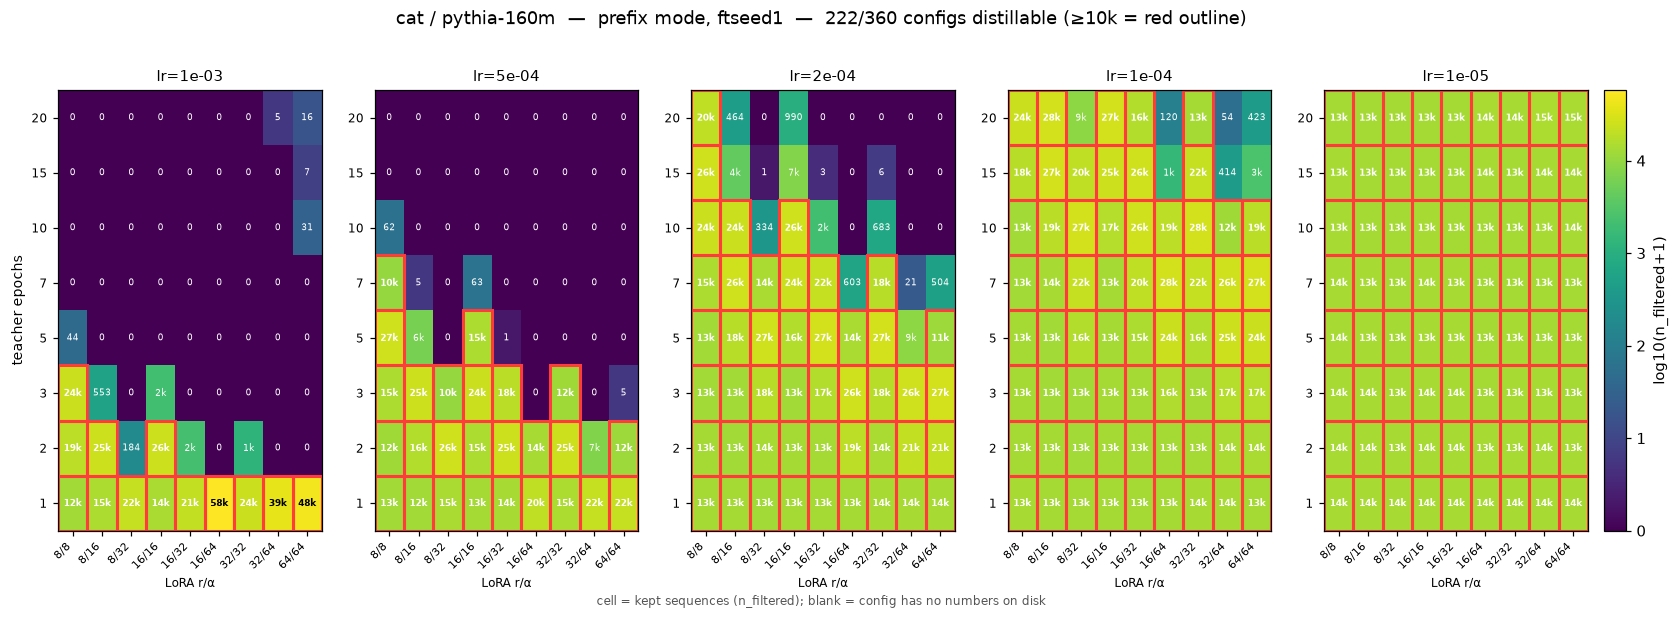

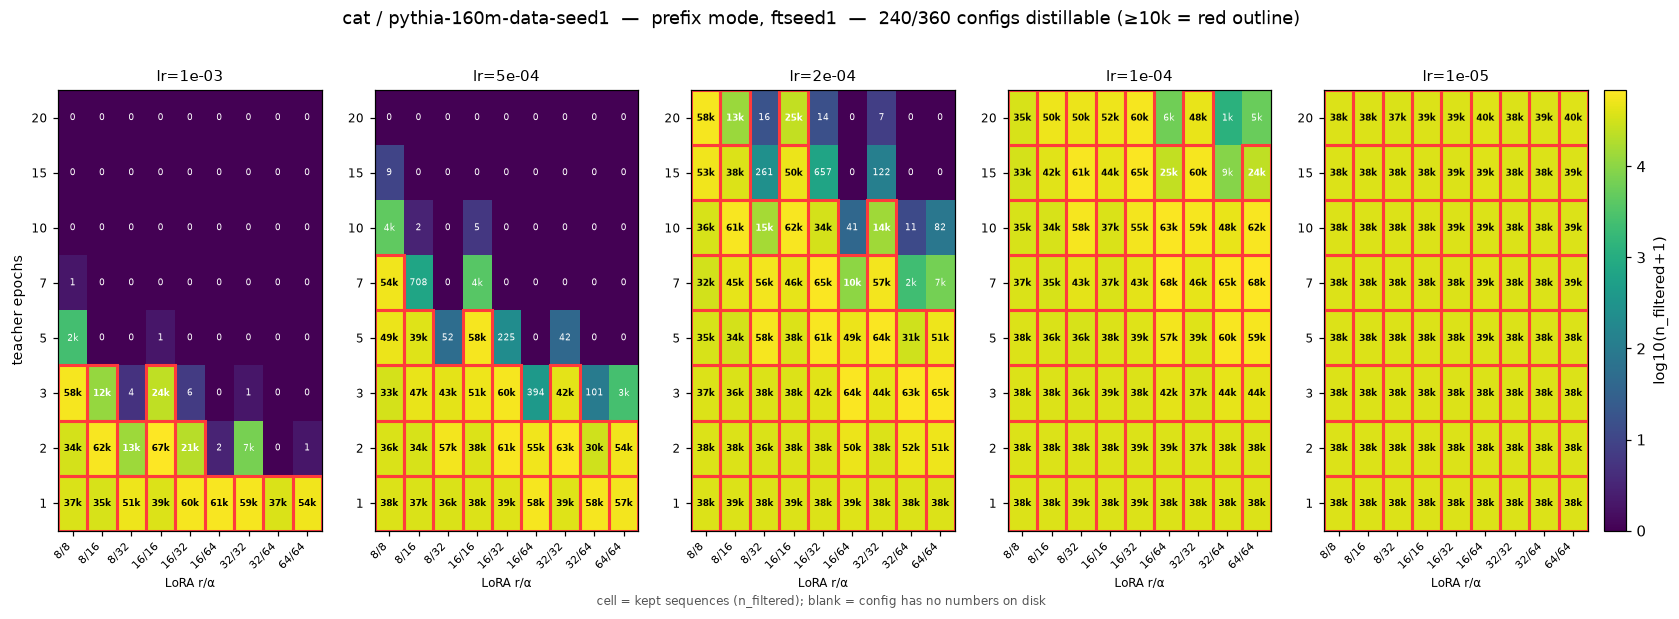

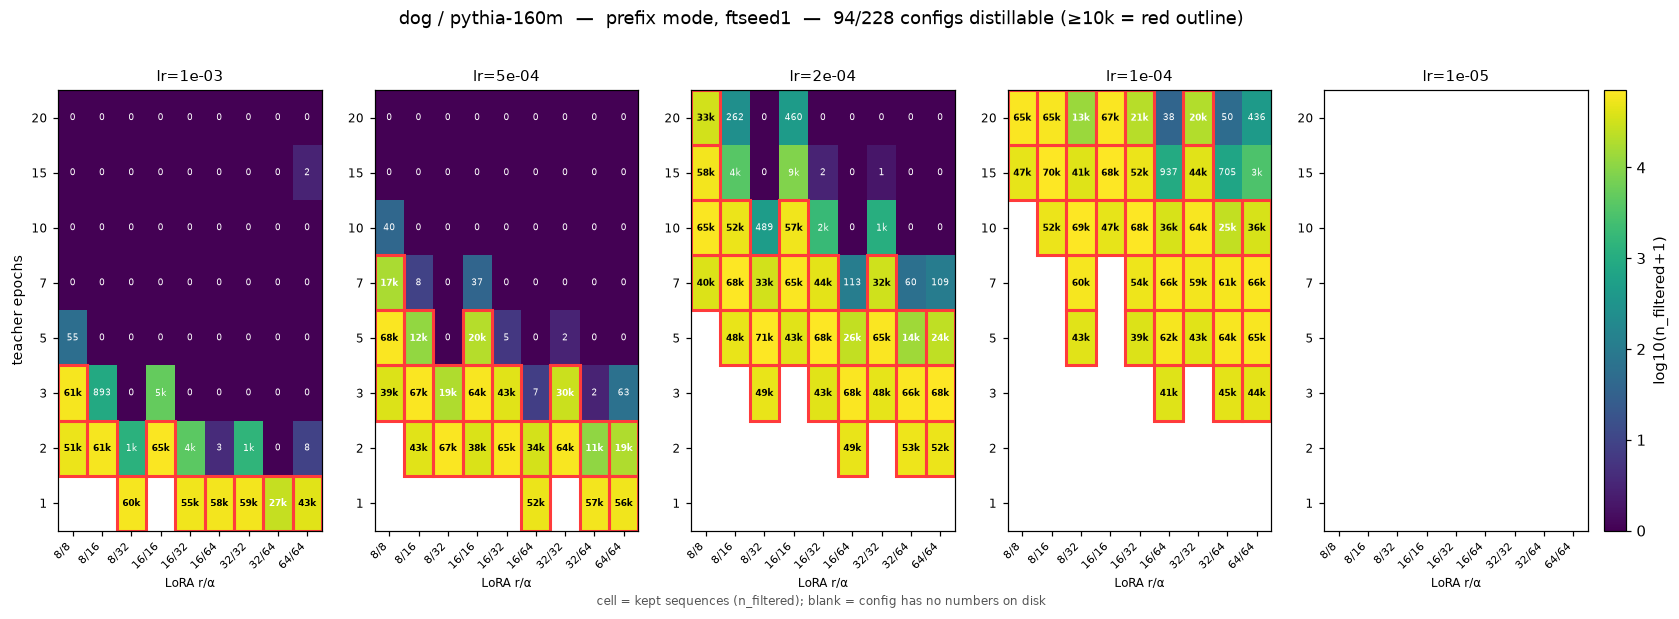

In [2]:
# Distillable-config heatmaps, one per (animal, base-model, lineage). MODE-filtered.
# Style matches §3 "Teacher hyperparameter surface" of the same-init distillation notebook:
# one row of subplots faceted by LEARNING RATE -- ascending left->right, the shared ordering
# of the sweep notebooks -- with LoRA (r/alpha) on the x-axis ordered by (r, alpha) and
# teacher epochs ascending on the y-axis.
from matplotlib.patches import Rectangle

HM_MODE     = "prefix"   # filter mode for the FILTERED lineage: prefix | full10 | full10_3digit
HM_FTSEED   = 1          # teacher ftseed (distillation seed; dog has only ftseed1)
DISTILL_MIN = 10_000     # >= this many kept sequences = distillable (student 10k subsample)

# Current teacher sweep (teacher_ft_sweep.yaml): rank x (alpha/r) crossed -> 12 r/alpha cells.
_SWEEP_LORAS = [(r, r * m) for r in (4, 8, 16, 32) for m in (1, 2, 4)]

def lineage_mode(ps_tag):
    """Display mode per lineage: HM_MODE for filtered pools; the single VERIFICATION mode
    for constrained ones (-c10 -> full10, -u10 -> prefix)."""
    if ps_tag == FILTERED_LINEAGE:
        return HM_MODE
    return "full10" if ps_tag.endswith("-c10") else "prefix"

def scan_mode_yield(numbers_root, ftseed):
    """One row per (teacher pool, filter mode) with n_filtered — ALL lineages and modes.
    Mode-aware (unlike scan_datasets, which keeps one stats_mode per pool)."""
    rows = []
    for mp in Path(numbers_root).rglob("modes/*/manifest.json"):
        if "_dryrun" in mp.parts:
            continue
        parts = mp.parent.relative_to(numbers_root).parts   # animal, model, tag, ftseedN, ps_tag, modes, mode
        if len(parts) < 7 or parts[0] == "controls" or parts[3] != f"ftseed{ftseed}":
            continue
        m = _TAG_RE.match(parts[2])
        if not m:
            continue
        try:
            nf = json.loads(mp.read_text()).get("n_filtered")
        except (OSError, json.JSONDecodeError):
            continue
        rows.append(dict(animal=parts[0], model=parts[1], param_tag=parts[2], ps_tag=parts[4],
                         mode=parts[6], n_epochs=int(m[1]), learning_rate=float(m[2]),
                         lora_r=int(m[3]), lora_alpha=int(m[4]), n_filtered=nf))
    return pd.DataFrame(rows, columns=["animal","model","param_tag","ps_tag","mode","n_epochs",
                                       "learning_rate","lora_r","lora_alpha","n_filtered"])

def hm_axes(df):
    """Shared display axes, each ASCENDING: frames.MAIN_GRID (epochs/LRs) ∪ the current sweep's
    r/α cells ∪ whatever exists on disk (legacy r64/α64 included)."""
    epochs = sorted(set(frames.MAIN_GRID["epochs"]) | set(df.n_epochs))
    lrs = sorted(set(frames.MAIN_GRID["lrs"]) | set(df.learning_rate))
    loras = sorted(set(_SWEEP_LORAS) | set(zip(df.lora_r, df.lora_alpha)))
    return epochs, lrs, loras

def distillable_heatmap(g, animal, model, ps_tag, mode, ftseed):
    ndist = int((g.n_filtered >= DISTILL_MIN).sum())
    vmax = float(np.log10(max(g.n_filtered.max(), 1) + 1))
    fig, axes = plt.subplots(1, len(_HM_LRS),
                             figsize=(0.42 * len(_HM_LORAS) * len(_HM_LRS) + 2, 5.4), squeeze=False)
    axes = axes.ravel(); im = None
    for k, lr in enumerate(_HM_LRS):
        ax = axes[k]; sub = g[np.isclose(g.learning_rate, lr)]
        M = np.full((len(_HM_EPOCHS), len(_HM_LORAS)), np.nan)
        for _, row in sub.iterrows():
            key = (row.lora_r, row.lora_alpha)
            if row.n_epochs in _HM_EPOCHS and key in _HM_LORAS:
                M[_HM_EPOCHS.index(row.n_epochs), _HM_LORAS.index(key)] = row.n_filtered
        im = ax.imshow(np.log10(M + 1), aspect="auto", cmap="viridis", origin="lower", vmin=0, vmax=vmax)
        ax.set_xticks(range(len(_HM_LORAS))); ax.set_xticklabels(_HM_LORALAB, fontsize=7, rotation=45, ha="right")
        ax.set_yticks(range(len(_HM_EPOCHS))); ax.set_yticklabels(_HM_EPOCHS, fontsize=8)
        ax.set_title(f"lr={lr:.0e}", fontsize=10)
        ax.set_xlabel("LoRA r/α", fontsize=8)
        if k == 0:
            ax.set_ylabel("teacher epochs", fontsize=9)
        ax.grid(False)
        for i in range(len(_HM_EPOCHS)):
            for j in range(len(_HM_LORAS)):
                v = M[i, j]
                if np.isnan(v):
                    continue
                dist = v >= DISTILL_MIN
                ax.text(j, i, f"{v/1000:.0f}k" if v >= 1000 else int(v), ha="center", va="center",
                        fontsize=6, color="white" if v < DISTILL_MIN * 3 else "black",
                        fontweight="bold" if dist else "normal")
                if dist:
                    ax.add_patch(Rectangle((j-0.5, i-0.5), 1, 1, fill=False, edgecolor="#ff3b3b", lw=2))
    fig.suptitle(f"{animal} / {model} / {ps_tag}  —  {mode} mode, ftseed{ftseed}  —  "
                 f"{ndist}/{len(g)} configs distillable (≥{DISTILL_MIN//1000}k = red outline)",
                 fontsize=12, y=1.02)
    if im is not None:
        fig.colorbar(im, ax=axes.tolist(), fraction=0.02, pad=0.01, label="log10(n_filtered+1)")
    fig.text(0.5, -0.02, "cell = kept sequences (n_filtered); blank = config has no numbers on disk",
             ha="center", fontsize=8, color="#555")
    plt.show()

_hm_all = scan_mode_yield(NUMBERS, HM_FTSEED)
_hm = _hm_all[_hm_all["mode"] == _hm_all.ps_tag.map(lineage_mode)].copy()
dup = _hm.duplicated(["animal", "model", "ps_tag", "param_tag"])
assert not dup.any(), \
    f"duplicate pools would overwrite heatmap cells: {_hm[dup][['animal','model','ps_tag','param_tag']].to_dict('records')[:5]}"
_HM_EPOCHS, _HM_LRS, _HM_LORAS = hm_axes(_hm)
_HM_LORALAB = [f"r{r}/α{a}" for r, a in _HM_LORAS]
print(f"axes: epochs={_HM_EPOCHS} | lrs={[f'{lr:.0e}' for lr in _HM_LRS]} (ascending) | "
      f"lora={_HM_LORALAB}")
print(f"ftseed={HM_FTSEED} — distillable(≥{DISTILL_MIN//1000}k)/total per (animal, model, lineage):")
for (a, md, t), gg in _hm.groupby(["animal", "model", "ps_tag"]):
    print(f"   {a}/{md}/{t} [{lineage_mode(t)}]: {int((gg.n_filtered>=DISTILL_MIN).sum())}/{len(gg)}")
for (a, md, t), g in _hm.groupby(["animal", "model", "ps_tag"]):
    distillable_heatmap(g, a, md, t, lineage_mode(t), HM_FTSEED)


## 10b. Constrained & spliced-prompt lineages  ⭐

Two new generation regimes (2026-07) live on their own `{ps_tag}` lineages next to the filtered
`ex10-20` pools:

| lineage | prompt | generation | filter mode |
|---|---|---|---|
| `ex10-20` | ICL (10–20 in-context examples) | free sampling → post-hoc filter | selection (`prefix` / `full10` / `full10_3digit`) |
| `ex10-20-c10` / `intro-c10` | ICL / intro | grammar-constrained, **exactly 10** numbers | `full10` — **verification only** |
| `ex10-20-u10` / `intro-u10` | ICL / intro | grammar-constrained, **up to 10** (early EOS offered at every number boundary) | `prefix` — **verification only** |

**Intro prompts are the spliced prompts:** no in-context examples, byte-identical to the
spliced-ICL prompts used by `--splice-examples` student training (`prompt_gen.build_intro_prompts`
is row-paired with the ICL set). A `LogitsProcessor` forces every token onto the number-list
grammar (`max_new_tokens` derived = 44), so **keep-rate is 1.0 by construction** — the single
filter mode verifies, it does not select. ⚠️ Constrained pools must **never** be compared against
filtered pools or across constrained modes — different data-generating processes, not an ablation
(see `configs/experiment/number_generation_{icl,intro}_{c10,u10}.yaml`).

Coverage at time of writing: **236 dog × original `intro-u10` pools** (ftseed1, 10k rows each —
all distillable); constrained **base/rng controls are not generated yet** (`_dryrun` only), so
constrained students currently have no distribution-matched control. §10 above facets by lineage,
so each constrained lineage gets its own heatmap figure as data lands.

For `-u10` the **model chooses where to stop**: `constrained_count_histogram` (top-level
manifest) records the resulting sequence-length distribution — the constrained-world analogue of
the §3 length confound (**#37**). If stronger teachers stop earlier, length still carries trait
signal even under a fixed grammar.

In [ ]:
# Constrained-pool inventory + verification (manifest-level; every pool, no row reads).
con = teach[teach.constrained].copy()
if not len(con):
    print("no constrained-lineage teacher pools on disk yet")
else:
    inv = con.groupby(["ps_tag", "animal", "model"]).agg(
        pools=("n_raw", "size"), n_raw=("n_raw", "sum"), n_filtered=("n_filtered", "sum"),
        keep_min=("keep_rate", "min"), keep_max=("keep_rate", "max"),
        mention_max=("mention_rate", "max")).reset_index()
    display(inv.style.format({"n_raw": "{:,}", "n_filtered": "{:,}", "keep_min": "{:.4f}",
                              "keep_max": "{:.4f}", "mention_max": "{:.4%}"}))
    bad = con[con.keep_rate.fillna(0) < 1.0]
    print(f"verification: {len(con)-len(bad)}/{len(con)} pools at keep-rate 1.0 "
          f"(grammar guarantees it; anything below 1.0 is a bug)")
    if len(bad):
        display(bad[["ps_tag","animal","model","param_tag","ftseed","n_raw","n_filtered","keep_rate"]]
                .reset_index(drop=True))
    # the grammar admits no words, so raw animal-mention should be exactly 0
    if con.mention_rate.fillna(0).max() > 0:
        print(f"⚠️ nonzero raw animal-mention rate in a constrained pool "
              f"(max={con.mention_rate.max():.4%}) — grammar should make this impossible")

In [ ]:
# -u10 sequence-length dose-response from constrained_count_histogram (no row reads):
# the constrained-world #37 view. LR lines ascending, matching the shared ordering.
u10 = teach[teach.ps_tag.str.endswith("-u10") & teach.count_hist.notna()].copy()
if not len(u10):
    print("no -u10 pools with a constrained_count_histogram yet")
else:
    def hist_arr(h):
        a = np.zeros(10)
        for k, v in h.items():
            a[int(k) - 1] = v
        return a
    H = np.stack([hist_arr(h) for h in u10.count_hist])
    u10["mean_count"] = (H * np.arange(1, 11)).sum(1) / H.sum(1)
    lineages = ", ".join(sorted(u10.ps_tag.unique()))
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    pooled = H.sum(0) / H.sum()
    axes[0].bar(np.arange(1, 11), pooled, color="#2a78d6")
    axes[0].set_xticks(range(1, 11)); axes[0].set_xlabel("numbers per completion")
    axes[0].set_ylabel("share of rows")
    axes[0].set_title(f"pooled count distribution ({lineages}; {len(u10)} pools)", fontsize=10)
    for lr in sorted(u10.learning_rate.unique()):
        g = u10[np.isclose(u10.learning_rate, lr)].groupby("n_epochs")["mean_count"].mean()
        axes[1].plot(g.index, g.values, marker="o", ms=3, label=f"lr={lr:.0e}")
    axes[1].set_xlabel("teacher epochs"); axes[1].set_ylabel("mean numbers per completion")
    axes[1].set_title("early stopping vs training dose (#37, constrained analogue)", fontsize=10)
    axes[1].legend(fontsize=8)   # LRs ascending, shared ordering
    fig.suptitle("-u10 lineages: where the model chooses to stop under the grammar", y=1.03)
    plt.tight_layout(); plt.show()
    display(u10.groupby(["ps_tag", "n_epochs"]).agg(
        mean_count=("mean_count", "mean"), pools=("mean_count", "size"))
        .style.format({"mean_count": "{:.2f}"}))

## 11. Disaggregated slices — fixing animal / model / smaller config slices  ⭐

Most of the sections above **pool hard**. This section keeps the same measurements but slices
them by **animal** and **base-model** (and, for yield, by training dose per animal) so a single
degenerate slice can't hide inside a source-level average.

**What each earlier section aggregates over ("which are aggregated"):**

| § | measurement | collapses over | already sliced by |
|---|---|---|---|
| §1 keep/mention | inventory table | `groupby(animal)` collapses model · HP · ftseed; the heatmap collapses **animal · model · LR · ftseed** into one (epochs × r/α) cell | — |
| §2 reject reasons | reject shares | **all** animals · models · HP · ftseed | source (teacher/base) |
| §3 length | pooled histogram | **all** teachers pooled; the dose plots collapse animal · model · LR (r/α kept explicit) | source |
| §4 value/digit | digit shares | **all** teachers pooled | source |
| §5 adequacy | table | nothing (one row per dataset) | — |
| §6 trait scatter | one dot per dataset | nothing | — |
| §7 strict/lenient | disposition shares | **all** teachers pooled (capped) | source |
| §8 base cmp | 2 base pools | n/a — whole pool per model | model |
| §9 teacher pools | pooled per side | **all** HP configs per side (**cat only**) | side; + per-config paired TV |
| §10 heatmaps | per-config yield | ftseed fixed at 1 | animal × model × LR × epochs × LoRA |

> **⚠️ Layout caveat that changes what §3–§4/§7 actually see.** The ROW-level sections read
> the **top-level** `filtered.jsonl`, which the **mode-based** pools (all **cat**,
> **dog-original**) do not have — their rows live under `modes/<mode>/`. So §3–§4/§7 silently
> read **empty** for those pools and effectively pool only the **old single-mode** pools
> (dog/pig data-seed1) plus the controls. (The MANIFEST-level sections §1/§2/§5/§6 *do* cover
> the mode pools: `scan_datasets` fills `n_filtered`/`keep_rate`/`reject_histogram` from
> `modes/<SCAN_MODE>/manifest.json` — see the `stats_mode` column.)
> §8–§10 read the mode files and do include cat/dog.
> Every slice below uses a **unified reader** covering *both* layouts, so cat and dog-original
> are represented. `SLICE_CAP_POOLS` / `SLICE_CAP_ROWS` cap the read for speed — bump them for
> precision.

**Scope:** slices below cover the **filtered `ex10-20` lineage** only (`SLICE_PS_TAG`;
constrained/spliced lineages are different data-generating processes — §10b) and **cat and dog**
only (the two animals with both base-models);
`SLICE_ANIMALS` controls this.

In [ ]:
# §11 unified two-layout scan. The top-level manifest/filtered.jsonl that §1-§4/§7 read is empty
# (n_filtered=None, no top-level filtered.jsonl) for the mode-based pools (all cat, dog-original);
# their data lives under modes/<mode>/. The OLD single-mode pools (dog/pig data-seed1) instead
# carry a top-level filtered.jsonl and no modes/ dir. This scan reads whichever exists, so every
# teacher pool is represented -- the basis for the disaggregated slices below.
SLICE_MODE      = "prefix"        # filter mode for all §11 slices
SLICE_PS_TAG    = FILTERED_LINEAGE  # lineage for all §11 slices (never pool across lineages)
SLICE_ANIMALS   = ["cat", "dog"]  # focus animals (both have both base-models; pig is ds1-only)
SLICE_CAP_POOLS = 40              # per (animal,model) slice: read at most this many pools ...
SLICE_CAP_ROWS  = 2000            # ... and this many rows per pool (keeps §11 fast; bump for precision)
DISTILL_MIN     = 10_000          # >= this many kept sequences = distillable (student 10k subsample)

def scan_teacher_pools(numbers_root, mode="prefix"):
    """One row per teacher pool across BOTH on-disk layouts (mode-based + old single-mode).
    `fpath` = the filtered.jsonl to read for that pool; `n_filtered` from its manifest."""
    rows, seen = [], set()
    for mp in Path(numbers_root).rglob(f"modes/{mode}/manifest.json"):        # new mode layout
        if "_dryrun" in mp.parts:
            continue
        base = mp.parent.parent.parent                                        # strip modes/<mode>
        parts = base.relative_to(numbers_root).parts                          # animal,model,tag,ftseedN,ps_tag
        if len(parts) < 5 or parts[0] == "controls" or not (m := _TAG_RE.match(parts[2])):
            continue
        try:
            nf = json.loads(mp.read_text()).get("n_filtered")
        except (OSError, json.JSONDecodeError):
            continue
        rows.append(dict(animal=parts[0], model=parts[1], param_tag=parts[2], ps_tag=parts[4],
            ftseed=int(parts[3].removeprefix("ftseed")) if parts[3].startswith("ftseed") else None,
            n_epochs=int(m[1]), learning_rate=float(m[2]), lora_r=int(m[3]), lora_alpha=int(m[4]),
            n_filtered=nf, layout="mode", fpath=str(mp.parent / "filtered.jsonl")))
        seen.add(str(base))
    if mode == "prefix":                                                      # old single-mode layout
        for mp in Path(numbers_root).rglob("manifest.json"):
            if "_dryrun" in mp.parts or "modes" in mp.parts:
                continue
            base = mp.parent
            if str(base) in seen or not (base / "filtered.jsonl").exists():
                continue
            parts = base.relative_to(numbers_root).parts
            if len(parts) < 5 or parts[0] == "controls" or not (m := _TAG_RE.match(parts[2])):
                continue
            try:
                nf = json.loads(mp.read_text()).get("n_filtered")
            except (OSError, json.JSONDecodeError):
                continue
            rows.append(dict(animal=parts[0], model=parts[1], param_tag=parts[2], ps_tag=parts[4],
                ftseed=int(parts[3].removeprefix("ftseed")) if parts[3].startswith("ftseed") else None,
                n_epochs=int(m[1]), learning_rate=float(m[2]), lora_r=int(m[3]), lora_alpha=int(m[4]),
                n_filtered=nf, layout="old", fpath=str(base / "filtered.jsonl")))
    df = pd.DataFrame(rows)
    df["model_s"] = (df.model.str.replace("pythia-160m-", "", regex=False)
                             .str.replace("pythia-160m", "original", regex=False))
    return df

tp = scan_teacher_pools(NUMBERS, SLICE_MODE)
tp = tp[tp.animal.isin(SLICE_ANIMALS) & (tp.ps_tag == SLICE_PS_TAG)].copy()
animals = [a for a in SLICE_ANIMALS if a in set(tp.animal)]
MODEL_COLOR = {"original": "#2a78d6", "data-seed1": "#e34948"}
print(f"{len(tp)} teacher pools ({SLICE_MODE} mode, {SLICE_PS_TAG} lineage; animals={animals}) across layouts: "
      + ", ".join(f"{k}={v}" for k, v in tp.layout.value_counts().items()))

# per (animal x model) inventory + distillability -- disaggregates the §1 groupby(animal) view
inv = tp.groupby(["animal", "model_s"]).agg(
    pools=("n_filtered", "size"),
    median_filtered=("n_filtered", "median"),
    max_filtered=("n_filtered", "max"),
    distillable=("n_filtered", lambda s: int((s >= DISTILL_MIN).sum())),
).reset_index()
inv["pct_distillable"] = inv.distillable / inv.pools
display(inv.style.format({"median_filtered": "{:,.0f}", "max_filtered": "{:,.0f}",
                          "pct_distillable": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(inv) + 1.2))
ax.barh(range(len(inv)), inv.pct_distillable, color="#2a78d6")
for i in range(len(inv)):
    ax.text(inv.pct_distillable.iloc[i] + 0.01, i, f"{inv.distillable.iloc[i]}/{inv.pools.iloc[i]}",
            va="center", fontsize=8)
ax.set_yticks(range(len(inv))); ax.set_yticklabels((inv.animal + " / " + inv.model_s).tolist())
ax.set_xlabel(f"share of pools >= {DISTILL_MIN//1000}k kept (distillable)"); ax.set_xlim(0, 1.12)
ax.set_title(f"Distillable pools per (animal, base-model) -- {SLICE_MODE} mode")
plt.tight_layout(); plt.show()

In [ ]:
# Kept-length distribution faceted by ANIMAL, split by base-model (disaggregates §3's
# pool-by-source view). Reads each pool's filtered.jsonl (mode or old layout), capped.
def read_lengths(fpath, cap):
    p = Path(fpath)
    if not p.exists():
        return []
    out = []
    for i, l in enumerate(p.read_text().splitlines()):
        if cap and i >= cap:
            break
        if l.strip():
            out.append(len(json.loads(l)["numbers"]))
    return out

def slice_lengths(sub):
    """Pooled kept-lengths for a slice, capped to SLICE_CAP_POOLS x SLICE_CAP_ROWS. Prefers the
    highest-yield pools so the sample reflects the data students would actually distil on."""
    L = []
    for fp in sub.sort_values("n_filtered", ascending=False)["fpath"].head(SLICE_CAP_POOLS):
        L.extend(read_lengths(fp, SLICE_CAP_ROWS))
    return np.array(L)

fig, axes = plt.subplots(1, len(animals), figsize=(4.8 * len(animals), 4.2), sharey=True, squeeze=False)
bins = np.arange(0.5, 11.5, 1)
for ax, a in zip(axes.ravel(), animals):
    for ms, col in MODEL_COLOR.items():
        L = slice_lengths(tp[(tp.animal == a) & (tp.model_s == ms) & (tp.n_filtered.fillna(0) > 0)])
        if len(L):
            ax.hist(L, bins=bins, density=True, alpha=0.5, color=col,
                    label=f"{ms}  (mean={L.mean():.2f}, %<10={(L<10).mean():.0%})")
    ax.set_title(a); ax.set_xlabel("kept sequence length"); ax.set_xticks(range(1, 11))
    ax.legend(fontsize=8)
axes.ravel()[0].set_ylabel("density")
fig.suptitle(f"Kept-length by animal x base-model ({SLICE_MODE} mode; "
             f"<= {SLICE_CAP_POOLS} pools x {SLICE_CAP_ROWS} rows each)", y=1.03)
plt.tight_layout(); plt.show()

In [ ]:
# Digit-count share (1/2/3-digit) per (animal x base-model) -- disaggregates §4's by-source view.
# slice_value_counts returns the full per-value (0-999) histogram, reused by the next cell too.
def slice_value_counts(sub):
    c = np.zeros(1000, dtype=np.int64)
    for fp in sub.sort_values("n_filtered", ascending=False)["fpath"].head(SLICE_CAP_POOLS):
        p = Path(fp)
        if not p.exists():
            continue
        for i, l in enumerate(p.read_text().splitlines()):
            if i >= SLICE_CAP_ROWS:
                break
            if l.strip():
                for v in json.loads(l)["numbers"]:
                    if 0 <= v < 1000:
                        c[v] += 1
    return c

rows = []
for (a, ms), sub in tp[tp.n_filtered.fillna(0) > 0].groupby(["animal", "model_s"]):
    c = slice_value_counts(sub)
    if c.sum():
        n = c.sum()
        rows.append(dict(slice=f"{a}/{ms}", n=int(n),
                         one=c[:10].sum()/n, two=c[10:100].sum()/n, three=c[100:].sum()/n))
dsh = pd.DataFrame(rows).set_index("slice")
display(dsh.style.format({"n": "{:,.0f}", "one": "{:.1%}", "two": "{:.1%}", "three": "{:.1%}"}))
ax = dsh[["one", "two", "three"]].plot(kind="barh", stacked=True, figsize=(9, 0.6 * len(dsh) + 1.5),
        color=["#d62728", "#ff7f0e", "#2ca02c"])
ax.set_xlabel("share of drawn numbers"); ax.set_xlim(0, 1)
ax.legend(["1-digit (<10)", "2-digit (10-99)", "3-digit (100-999)"], fontsize=8, loc="lower right")
ax.set_title(f"Digit-count share by animal x base-model ({SLICE_MODE} mode)")
plt.tight_layout(); plt.show()

In [ ]:
# Per-animal value distribution: original vs data-seed1 -- the §8/§9 base-gap check, but sliced by
# animal instead of pooling all cat teachers. TV/JS on the exact per-value (0-999) histograms
# (same metric as §8's tv_js: TV = 0.5 * sum|p-q|, JS in bits). Reuses slice_value_counts (c4).
def _tv_js(pc, qc):
    p = pc / pc.sum(); q = qc / qc.sum(); m = 0.5 * (p + q)
    kl = lambda a, b: float((a[a > 0] * np.log2(a[a > 0] / b[a > 0])).sum())
    return 0.5 * float(np.abs(p - q).sum()), 0.5 * kl(p, m) + 0.5 * kl(q, m)

pair_animals = [a for a in animals
                if {"original", "data-seed1"} <= set(tp[(tp.animal == a) & (tp.n_filtered.fillna(0) > 0)].model_s)]
fig, axes = plt.subplots(1, max(len(pair_animals), 1),
                         figsize=(5.4 * max(len(pair_animals), 1), 4.2), squeeze=False)
bins = np.arange(0, 1001, 20)
for ax, a in zip(axes.ravel(), pair_animals):
    counts = {}
    for ms, col in MODEL_COLOR.items():
        c = slice_value_counts(tp[(tp.animal == a) & (tp.model_s == ms) & (tp.n_filtered.fillna(0) > 0)])
        counts[ms] = c
        ax.hist(np.repeat(np.arange(1000), c), bins=bins, density=True, alpha=0.5, color=col,
                label=f"{ms} (n={c.sum():,})")
    tv, js = _tv_js(counts["original"], counts["data-seed1"])
    ax.set_title(f"{a}  |  TV={tv:.3f}, JS={js:.3f} bits", fontsize=10)
    ax.set_xlabel("value"); ax.legend(fontsize=8)
axes.ravel()[0].set_ylabel("density")
fig.suptitle(f"Value distribution original vs data-seed1, per animal ({SLICE_MODE} mode) -- "
             f"the §8/§9 base gap, sliced by animal", y=1.03)
plt.tight_layout(); plt.show()

In [ ]:
# Yield (kept sequences) vs training dose, faceted by ANIMAL -- collapses §10's per-config heatmaps
# to a median-yield line per base-model so the epoch trend per animal is legible. Cheap: manifest
# n_filtered only, no row reads. Red line = the distillable floor.
fig, axes = plt.subplots(1, len(animals), figsize=(5.0 * len(animals), 4.2), sharey=True, squeeze=False)
for ax, a in zip(axes.ravel(), animals):
    sub = tp[tp.animal == a]
    for ms, col in MODEL_COLOR.items():
        s2 = sub[sub.model_s == ms]
        if not len(s2):
            continue
        g = s2.groupby("n_epochs").n_filtered.median().replace(0, np.nan).dropna()
        if len(g):
            ax.plot(g.index, g.values, marker="o", color=col, label=f"{ms} (n={len(s2)} pools)")
    ax.axhline(DISTILL_MIN, color="#ff3b3b", ls="--", lw=1)
    ax.set_yscale("log"); ax.set_title(a); ax.set_xlabel("teacher epochs"); ax.legend(fontsize=8)
axes.ravel()[0].set_ylabel("median kept sequences (log)")
fig.suptitle(f"Yield vs training dose per animal ({SLICE_MODE} mode) -- "
             f"red = {DISTILL_MIN//1000}k distillable floor", y=1.03)
plt.tight_layout(); plt.show()